# Piled-Garbage Detection on the Rajshahi University Campus
## DETR vs. DINO vs. RT-DETR vs. Grounding DINO (PyTorch, Google Colab)

This notebook is a complete, re-runnable pipeline for the assignment: it audits your annotated RU-campus dataset, defines the augmentation, fine-tunes the detectors, evaluates them under one common protocol, compares them with their original pretrained versions, studies Grounding DINO with text prompts, and prepares tables and figures for the report.

**Runtime:** Colab with a GPU (T4 is enough). `Runtime -> Change runtime type -> GPU`.

### How the assignment tasks map to this notebook

| Assignment task | Section |
|---|---|
| 1. Custom dataset collection | You did this; Section 1 documents it (size, boxes per image, image properties, capture-time statistics) |
| 2. Annotation and preparation | Section 1 (validation of your COCO files, split table, leakage checks) |
| 3. Data augmentation | Section 2 |
| 4. Model implementation and fine-tuning | Sections 3, 5, 6 (DETR, RT-DETR), 8 (DINO), 9 (Grounding DINO) |
| 5. Performance evaluation (P, R, mAP, FPS, latency) | Section 4 (metrics) and Section 7 (running them) |
| 6. Original pretrained vs. fine-tuned | Sections 7.1, 8, 9 and 10.2 |
| 7. Comparative analysis and failure cases | Sections 10 and 11 |
| 8. Optional text-prompt interface | Sections 9.3 (prompt-wording study) and 9.4 (Gradio) |
| Report: qualitative results, curves, tables | Sections 10 to 12 produce the figures and CSV tables |

### Design decisions you should know about
* **Single class.** `piled_garbage`. Boxes come from your Make Sense polygons (`bbox` field of the COCO file).
* **One evaluation protocol for every model.** The same held-out test images, the same COCO-style AP code, the same IoU = 0.5 matching for precision and recall, and the same confidence-threshold rule (tuned on the validation set, never on the test set).
* **DETR and RT-DETR use Hugging Face `transformers`** models and one shared training loop written in plain PyTorch. **DINO uses the official IDEA-Research code** (there is no DINO-DETR in `transformers`) run as a separate process. **Grounding DINO** uses `transformers`.
* **Resolution.** All Hugging Face detectors take a fixed square input (640 x 640 for DETR and RT-DETR, 800 x 800 for Grounding DINO). Official DINO keeps its own aspect-preserving resize (short side 800). This difference is reported in the setup table.
* **Original pretrained models cannot output "piled garbage"** (the class is not in COCO). For them the notebook reports a *class-agnostic* baseline: every detection of any COCO class is treated as a garbage candidate. This is a lower bound, not a fair class-aware score; Section 7.1 explains how to read it.



## 0. Setup

In [ ]:
!pip -q install "transformers>=4.45" accelerate albumentations pycocotools timm scipy gradio addict yapf termcolor opencv-python-headless tqdm

In [ ]:
import os, sys, io, json, math, time, random, shutil, copy, gc, re, glob, subprocess, contextlib, warnings
from pathlib import Path
from collections import defaultdict, Counter
from time import perf_counter

import numpy as np
import pandas as pd
import cv2
import torch, torch.nn as nn
import torchvision
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import albumentations as A
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

warnings.filterwarnings('ignore')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
assert DEVICE == 'cuda', 'Please switch the Colab runtime to a GPU.'
GPU_NAME = torch.cuda.get_device_name(0)
import transformers
print('torch', torch.__version__, '| torchvision', torchvision.__version__, '| transformers', transformers.__version__,
      '| albumentations', A.__version__)
print('GPU:', GPU_NAME, '| memory (GB):', round(torch.cuda.get_device_properties(0).total_memory/2**30, 1))

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | transformers 5.18.0 | albumentations 2.0.8
GPU: Tesla T4 | memory (GB): 14.6


In [ ]:
# -----------------------------------------------------------------------------
# Google Drive paths (match the structure you described)
# -----------------------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

QUICK_TEST = False   # True: 2 epochs per model, only to check that every cell runs (results go to Experiments_quicktest, not Experiments)
ROOT       = Path('/content/drive/MyDrive/Ru_Garbase')
IMG_DIR    = ROOT / 'Original_images'
COCO_DIR   = ROOT / 'COCO_Splits'
SPLIT_JSON = ROOT / 'Dataset_Split' / 'split_files.json'
OUT        = ROOT / ('Experiments_quicktest' if QUICK_TEST else 'Experiments')   # everything produced by this notebook goes here
FIG_DIR    = OUT / 'figures'
for d in (OUT, FIG_DIR): d.mkdir(parents=True, exist_ok=True)
for p in (IMG_DIR, COCO_DIR / 'train_annotations.json', COCO_DIR / 'val_annotations.json', COCO_DIR / 'test_annotations.json'):
    print('OK ' if p.exists() else 'MISSING', p)

# -----------------------------------------------------------------------------
# Global settings
# -----------------------------------------------------------------------------
SEED            = 42
CACHE_MAX_SIDE  = 1024    # images are cached in RAM with the long side limited to this value
IOU_MATCH       = 0.5     # IoU used to count a detection as correct (precision / recall)
CONF_FIXED      = 0.5     # a second, fixed confidence threshold reported next to the tuned one
CAT_ID, CAT_NAME = 1, 'piled_garbage'

def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()

def savefig(name):
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

Mounted at /content/drive
OK  /content/drive/MyDrive/Ru_Garbase/Original_images
OK  /content/drive/MyDrive/Ru_Garbase/COCO_Splits/train_annotations.json
OK  /content/drive/MyDrive/Ru_Garbase/COCO_Splits/val_annotations.json
OK  /content/drive/MyDrive/Ru_Garbase/COCO_Splits/test_annotations.json


## 1. Dataset audit and preparation (Tasks 1 and 2)

The notebook loads your three COCO split files and **rebuilds clean versions in memory**:

* the category is forced to a single class `piled_garbage` (id 1), which also fixes the old `piled_garbase` spelling if it is still present in a file;
* every box is checked and clipped to the image, and degenerate boxes are reported;
* `area` is replaced by the box area (`w * h`) so that the COCO evaluation is purely box-based (polygon areas from Make Sense would otherwise be used);
* images get new global ids, so ids can never collide between splits.

The polygons (`segmentation`) are not used for training, but they are kept in your original files.

In [ ]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
IMG_LOOKUP = {p.name.lower(): p for p in IMG_DIR.iterdir() if p.suffix.lower() in IMG_EXT}
print('image files found in Original_images:', len(IMG_LOOKUP))

def read_json(p):
    with open(p) as f: return json.load(f)

def clean_split(raw, split, gid_start):
    """Turn one raw COCO dict into a list of records (one per image)."""
    imgs = {im['id']: im for im in raw['images']}
    boxes = defaultdict(list); issues = Counter()
    for a in raw['annotations']:
        im = imgs.get(a['image_id'])
        if im is None: issues['annotation without image'] += 1; continue
        x, y, w, h = a['bbox']
        x1, y1 = max(0.0, x), max(0.0, y)
        x2, y2 = min(float(im['width']), x + w), min(float(im['height']), y + h)
        if x2 - x1 < 2 or y2 - y1 < 2: issues['degenerate box dropped'] += 1; continue
        if (x1, y1, x2, y2) != (x, y, x + w, y + h): issues['box clipped to image'] += 1
        boxes[a['image_id']].append([x1, y1, x2 - x1, y2 - y1])
    records, gid = [], gid_start
    for iid, im in imgs.items():
        p = IMG_LOOKUP.get(Path(im['file_name']).name.lower())
        if p is None: issues['image file missing'] += 1; continue
        records.append(dict(split=split, image_id=gid, orig_id=iid, file_name=p.name, path=str(p),
                            W=int(im['width']), H=int(im['height']),
                            boxes=np.array(boxes[iid], dtype=np.float64).reshape(-1, 4)))
        gid += 1
    return records, issues

raw = {s: read_json(COCO_DIR / f'{s}_annotations.json') for s in ('train', 'val', 'test')}
print('categories in the raw files:', {s: [(c['id'], c['name']) for c in raw[s]['categories']] for s in raw})

SPLITS, all_issues, gid = {}, {}, 1
for s in ('train', 'val', 'test'):
    SPLITS[s], all_issues[s] = clean_split(raw[s], s, gid)
    gid += len(SPLITS[s])
TRAIN, VAL, TEST = SPLITS['train'], SPLITS['val'], SPLITS['test']
ALL_RECORDS = TRAIN + VAL + TEST
print('issues found while cleaning:', {s: dict(v) for s, v in all_issues.items()})

def build_gt_coco(records):
    images, anns, k = [], [], 1
    for r in records:
        images.append(dict(id=r['image_id'], file_name=r['file_name'], width=r['W'], height=r['H']))
        for x, y, w, h in r['boxes']:
            anns.append(dict(id=k, image_id=r['image_id'], category_id=CAT_ID, bbox=[x, y, w, h],
                             area=w * h, iscrowd=0)); k += 1
    return dict(images=images, annotations=anns, categories=[dict(id=CAT_ID, name=CAT_NAME)])

GT = {s: build_gt_coco(SPLITS[s]) for s in SPLITS}

if SPLIT_JSON.exists():
    sj = read_json(SPLIT_JSON)
    print('split_files.json top-level keys:', list(sj.keys()) if isinstance(sj, dict) else type(sj))

image files found in Original_images: 154
categories in the raw files: {'train': [(1, 'piled_garbase')], 'val': [(1, 'piled_garbase')], 'test': [(1, 'piled_garbase')]}
issues found while cleaning: {'train': {}, 'val': {}, 'test': {}}
split_files.json top-level keys: ['train', 'val', 'test']


### 1.1 Dataset statistics (size, class distribution, split strategy)

In [ ]:
rows = []
for s in ('train', 'val', 'test'):
    recs = SPLITS[s]; nb = [len(r['boxes']) for r in recs]
    frac = [(b[2] * b[3]) / (r['W'] * r['H']) for r in recs for b in r['boxes']]
    rows.append(dict(split=s, images=len(recs), boxes=int(sum(nb)), boxes_per_image=round(np.mean(nb), 2),
                     images_with_no_box=int(sum(n == 0 for n in nb)),
                     median_box_area_pct=round(100 * np.median(frac), 1) if frac else np.nan,
                     min_box_area_pct=round(100 * np.min(frac), 2) if frac else np.nan,
                     max_box_area_pct=round(100 * np.max(frac), 1) if frac else np.nan))
rows.append(dict(split='ALL', images=len(ALL_RECORDS), boxes=sum(r['boxes'] for r in rows), **{k: '' for k in list(rows[0])[3:]}))
df_split = pd.DataFrame(rows).set_index('split')
display(df_split)
df_split.to_csv(OUT / 'dataset_split_table.csv')

if len(TEST) < 25:
    print(f'NOTE: the test set has only {len(TEST)} images. Differences of a few AP points between models are then within noise;'
          ' the report should say so and the bootstrap intervals in Section 7 should be quoted.')

,images,boxes,boxes_per_image,images_with_no_box,median_box_area_pct,min_box_area_pct,max_box_area_pct
split,,,,,,,
train,105,107,1.02,0,71.2,0.15,100.0
val,25,25,1.0,0,67.5,3.57,97.5
test,24,24,1.0,0,60.2,16.26,98.9
ALL,154,156,,,,,


NOTE: the test set has only 24 images. Differences of a few AP points between models are then within noise; the report should say so and the bootstrap intervals in Section 7 should be quoted.


### 1.2 Load and cache the images; check image sizes against the annotation file

Smartphone photos often carry an **EXIF orientation flag**. Browsers (and therefore Make Sense) show the rotated image, but plain image libraries ignore the flag, which would silently turn every box. The loader below compares the stored size with the size in the COCO file and applies the EXIF rotation only when that makes them agree.

Images are then stored in RAM with the long side limited to `CACHE_MAX_SIDE`; boxes keep their original-image coordinates and are scaled when needed.

In [ ]:
def load_rgb(path, W, H):
    im = Image.open(path)
    status = 'ok'
    if im.size != (W, H):
        t = ImageOps.exif_transpose(im)
        if t.size == (W, H): im, status = t, 'exif-rotated'
        else:                im, status = t, 'SIZE MISMATCH'
    return np.array(im.convert('RGB')), status

IMG_CACHE, status_count, mismatches = {}, Counter(), []
for r in tqdm(ALL_RECORDS, desc='caching images'):
    arr, st = load_rgb(r['path'], r['W'], r['H']); status_count[st] += 1
    if st == 'SIZE MISMATCH': mismatches.append((r['file_name'], (r['W'], r['H']), arr.shape[:2][::-1]))
    h, w = arr.shape[:2]; s = min(1.0, CACHE_MAX_SIDE / max(h, w))
    if s < 1: arr = cv2.resize(arr, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    ch, cw = arr.shape[:2]
    IMG_CACHE[r['file_name']] = dict(img=arr, fx=cw / r['W'], fy=ch / r['H'])
print('image size check:', dict(status_count))
if mismatches: print('first mismatches (file, json WxH, actual WxH):', mismatches[:5])
sizes = pd.Series([f"{r['W']}x{r['H']}" for r in ALL_RECORDS]).value_counts()
print('most common image sizes:\n', sizes.head(5).to_string())

caching images:   0%|          | 0/154 [00:00<?, ?it/s]

image size check: {'ok': 126, 'exif-rotated': 28}
most common image sizes:
 3060x4080    68
1800x4000    28
1200x1600    27
1600x1200    22
4080x3060     7


### 1.3 Data-leakage checks

The assignment asks to keep images of the same location or capture session in one split. Two quick checks that need no extra labels:

1. **Near-duplicate images** across splits (difference hash). Photos of the same pile from a slightly different position often end up in train and test.
2. **EXIF capture time** (if the photos still carry it). A test image taken minutes after a training image probably shows the same place.

If either check finds problems, say so in the report; a stricter fix is to regroup the images by location and re-split.

In [ ]:
def dhash(img, n=8):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY); g = cv2.resize(g, (n + 1, n), interpolation=cv2.INTER_AREA)
    return (g[:, 1:] > g[:, :-1]).flatten()

H_ = {r['file_name']: dhash(IMG_CACHE[r['file_name']]['img']) for r in ALL_RECORDS}
def near_dups(A_recs, B_recs, max_ham=6):
    out = []
    for a in A_recs:
        for b in B_recs:
            d = int((H_[a['file_name']] != H_[b['file_name']]).sum())
            if d <= max_ham: out.append((a['file_name'], b['file_name'], d))
    return out

dups = {'test~train': near_dups(TEST, TRAIN), 'val~train': near_dups(VAL, TRAIN), 'test~val': near_dups(TEST, VAL)}
for k, v in dups.items(): print(f'near-duplicate pairs {k}: {len(v)}', v[:4])

def exif_time(path):
    try:
        ex = Image.open(path).getexif(); v = ex.get_ifd(0x8769).get(36867) or ex.get(306)
        return pd.to_datetime(v, format='%Y:%m:%d %H:%M:%S') if v else pd.NaT
    except Exception: return pd.NaT

T_ = {r['file_name']: exif_time(r['path']) for r in ALL_RECORDS}
have = sum(pd.notna(v) for v in T_.values()); print(f'\nimages with an EXIF capture time: {have}/{len(T_)}')
if have > 0.5 * len(T_):
    tr_t = pd.Series({r['file_name']: T_[r['file_name']] for r in TRAIN}).dropna()
    gaps = []
    for r in TEST:
        t = T_[r['file_name']]
        if pd.notna(t) and len(tr_t): gaps.append(abs((tr_t - t).dt.total_seconds()).min() / 60)
    if gaps: print(f'time to the nearest TRAIN image for each TEST image (minutes): median {np.median(gaps):.1f}, '
                   f'min {np.min(gaps):.1f}, share within 10 min: {np.mean(np.array(gaps) < 10):.0%}')

if dups['test~train']:
    fig, axs = plt.subplots(len(dups['test~train'][:3]), 2, figsize=(8, 3 * len(dups['test~train'][:3])), squeeze=False)
    for ax, (a, b, d) in zip(axs, dups['test~train'][:3]):
        ax[0].imshow(IMG_CACHE[a]['img']); ax[0].set_title(f'TEST {a}', fontsize=8)
        ax[1].imshow(IMG_CACHE[b]['img']); ax[1].set_title(f'TRAIN {b} (hamming {d})', fontsize=8)
        ax[0].axis('off'); ax[1].axis('off')
    plt.tight_layout(); savefig('leakage_near_duplicates'); plt.show()

near-duplicate pairs test~train: 0 []
near-duplicate pairs val~train: 0 []
near-duplicate pairs test~val: 0 []

images with an EXIF capture time: 105/154
time to the nearest TRAIN image for each TEST image (minutes): median 0.4, min 0.0, share within 10 min: 100%


### 1.4 Per-image descriptors for the robustness analysis (Task 7)

The assignment asks how illumination, background, pile size, occlusion and viewing angle affect detection. You did not label those, so the notebook computes **automatic proxies** from the images and the boxes, and splits them into three equal-sized bins:

| Factor | Proxy |
|---|---|
| pile size | largest box area / image area |
| illumination | mean brightness (HSV value channel) |
| contrast | grey-level standard deviation |
| background clutter | share of edge pixels (Canny) |
| number of piles | boxes per image |

**Optional and recommended:** for the factors that cannot be measured automatically (weather, location, background type, occlusion, viewing angle, garbage type), fill in the template CSV that the next cell writes to your Drive, save it as `Ru_Garbase/image_metadata.csv`, and re-run from this cell. Any extra columns will be used automatically in Section 10.

In [ ]:
def image_features(r):
    img = IMG_CACHE[r['file_name']]['img']
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV); gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    fr = [(w * h) / (r['W'] * r['H']) for _, _, w, h in r['boxes']]
    return dict(file_name=r['file_name'], split=r['split'], brightness=hsv[..., 2].mean() / 255, contrast=gray.std() / 255,
                saturation=hsv[..., 1].mean() / 255, edge_density=(cv2.Canny(gray, 100, 200) > 0).mean(),
                pile_frac=max(fr) if fr else np.nan, n_piles=len(fr), aspect=r['W'] / r['H'])

FEAT = pd.DataFrame([image_features(r) for r in ALL_RECORDS]).set_index('file_name')
def tertile(s, labels): return pd.qcut(s.rank(method='first'), 3, labels=labels)
FEAT['pile_size_bin']    = tertile(FEAT['pile_frac'],    ['small pile', 'medium pile', 'large pile'])
FEAT['illumination_bin'] = tertile(FEAT['brightness'],   ['dark', 'medium light', 'bright'])
FEAT['clutter_bin']      = tertile(FEAT['edge_density'], ['smooth background', 'medium clutter', 'cluttered'])
FEAT['contrast_bin']     = tertile(FEAT['contrast'],     ['low contrast', 'medium contrast', 'high contrast'])

META_CSV = ROOT / 'image_metadata.csv'
if META_CSV.exists():
    META = pd.read_csv(META_CSV).set_index('file_name'); FEAT = FEAT.join(META, how='left', rsuffix='_user')
    print('user metadata merged; extra columns:', list(META.columns))
else:
    tmpl = pd.DataFrame({'file_name': [r['file_name'] for r in ALL_RECORDS], 'location': '', 'weather': '', 'background': '',
                         'occlusion': '', 'view_angle': '', 'garbage_type': ''})
    tmpl.to_csv(ROOT / 'image_metadata_template.csv', index=False)
    print('no image_metadata.csv found; a blank template was written to', ROOT / 'image_metadata_template.csv')
FEAT.to_csv(OUT / 'image_features.csv')
display(FEAT.groupby('split')[['brightness', 'contrast', 'edge_density', 'pile_frac', 'n_piles']].describe().T.round(3).iloc[:, :].head(25))

no image_metadata.csv found; a blank template was written to /content/drive/MyDrive/Ru_Garbase/image_metadata_template.csv


split                 test    train     val
brightness   count  24.000  105.000  25.000
             mean    0.511    0.523   0.517
             std     0.053    0.053   0.044
             min     0.412    0.374   0.439
             25%     0.464    0.487   0.483
             50%     0.517    0.526   0.512
             75%     0.556    0.556   0.549
             max     0.585    0.670   0.592
contrast     count  24.000  105.000  25.000
             mean    0.210    0.219   0.206
             std     0.033    0.032   0.028
             min     0.144    0.138   0.145
             25%     0.197    0.198   0.188
             50%     0.215    0.223   0.202
             75%     0.231    0.241   0.218
             max     0.271    0.283   0.278
edge_density count  24.000  105.000  25.000
             mean    0.209    0.209   0.176
             std     0.068    0.082   0.079
             min     0.078    0.003   0.042
             25%     0.166    0.173   0.117
             50%     0.186    0.228   0.168
             75%     0.251    0.270   0.250
             max     0.333    0.344   0.300
pile_frac    count  24.000  105.000  25.000

### 1.5 Look at the data

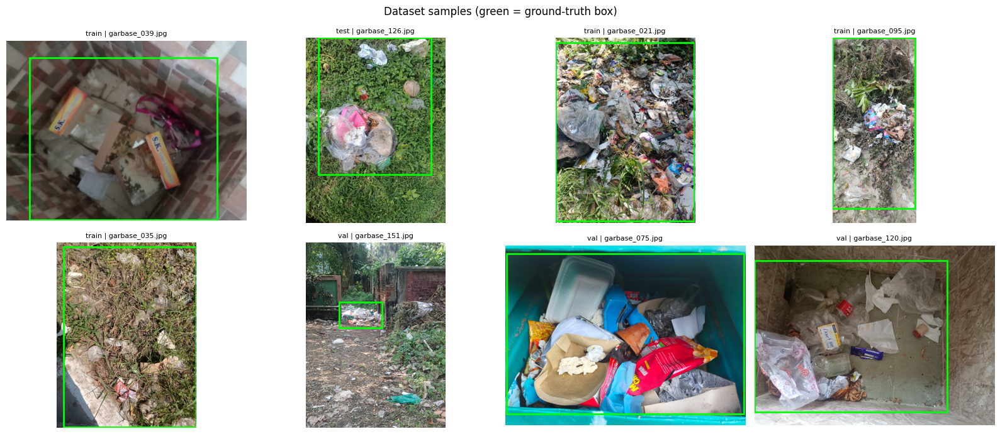

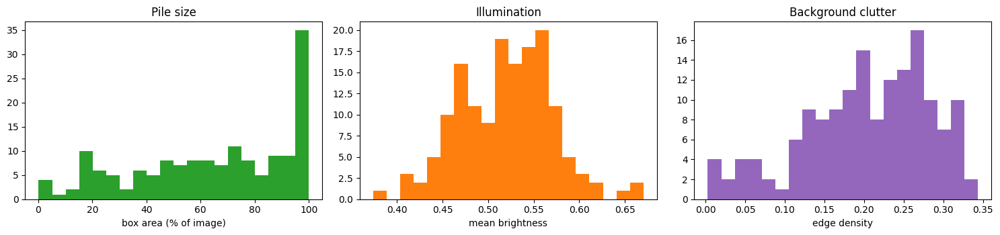

In [ ]:
def xywh2xyxy(b):
    b = np.asarray(b, float).reshape(-1, 4); return np.c_[b[:, 0], b[:, 1], b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]]

def draw_on(ax, rec, gt=True, dets=None, thr=0.0, title=None, fs=7):
    """Draw GT (green) and detections (red) in original-image coordinates on the cached image."""
    c = IMG_CACHE[rec['file_name']]; ax.imshow(c['img']); ax.axis('off')
    if gt:
        for x1, y1, x2, y2 in xywh2xyxy(rec['boxes']):
            ax.add_patch(plt.Rectangle((x1 * c['fx'], y1 * c['fy']), (x2 - x1) * c['fx'], (y2 - y1) * c['fy'], fill=False, ec='lime', lw=2))
    if dets is not None:
        for (x1, y1, x2, y2), s in zip(dets['boxes'], dets['scores']):
            if s < thr: continue
            ax.add_patch(plt.Rectangle((x1 * c['fx'], y1 * c['fy']), (x2 - x1) * c['fx'], (y2 - y1) * c['fy'], fill=False, ec='red', lw=2, ls='--'))
            ax.text(x1 * c['fx'], max(0, y1 * c['fy'] - 4), f'{s:.2f}', color='white', fontsize=fs, bbox=dict(fc='red', ec='none', pad=1))
    ax.set_title(title if title is not None else rec['file_name'], fontsize=fs + 1)

rng = random.Random(1); show = rng.sample(ALL_RECORDS, min(8, len(ALL_RECORDS)))
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, r in zip(axs.ravel(), show): draw_on(ax, r, title=f"{r['split']} | {r['file_name']}")
plt.suptitle('Dataset samples (green = ground-truth box)'); plt.tight_layout(); savefig('dataset_samples'); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
fr = [100 * (b[2] * b[3]) / (r['W'] * r['H']) for r in ALL_RECORDS for b in r['boxes']]
axs[0].hist(fr, bins=20, color='tab:green'); axs[0].set_xlabel('box area (% of image)'); axs[0].set_title('Pile size')
axs[1].hist(FEAT['brightness'], bins=20, color='tab:orange'); axs[1].set_xlabel('mean brightness'); axs[1].set_title('Illumination')
axs[2].hist(FEAT['edge_density'], bins=20, color='tab:purple'); axs[2].set_xlabel('edge density'); axs[2].set_title('Background clutter')
plt.tight_layout(); savefig('dataset_distributions'); plt.show()

## 2. Data augmentation (Task 3)

Training uses `albumentations`, which transforms the image and the boxes together, so annotations stay consistent. Validation and test images only get the final resize.

| Transform | Why it helps for piled garbage |
|---|---|
| Horizontal flip | Piles have no preferred side; doubles the layouts seen. |
| Box-safe random crop | Changes pile size and distance from the camera, but never cuts a pile out of the image. |
| Affine (scale 0.8-1.2, shift up to 10 %, rotation up to 8 degrees) | Simulates different camera positions and viewing angles, and piles at the image border. |
| Brightness / contrast, gamma, hue-saturation | Early morning, midday and cloudy light; differently coloured bags and wrappers. |
| Random shadow | Shadows from trees and buildings are common on campus. |
| Gaussian and motion blur | Hand-held phones; out-of-focus piles at a distance. |

Choices that were **left out on purpose**: vertical flips and large rotations (piles do not appear upside-down), and mosaic / mix-up (they create unrealistic pile layouts and are not supported by the DETR loss implementations used here in a simple way). Boxes whose visible share drops below 30 % after a transform are removed, and a training sample is re-drawn (up to five times) if no box is left.

The ablation experiment `rtdetr_r50vd_noaug` in Section 6 measures what augmentation actually contributes.

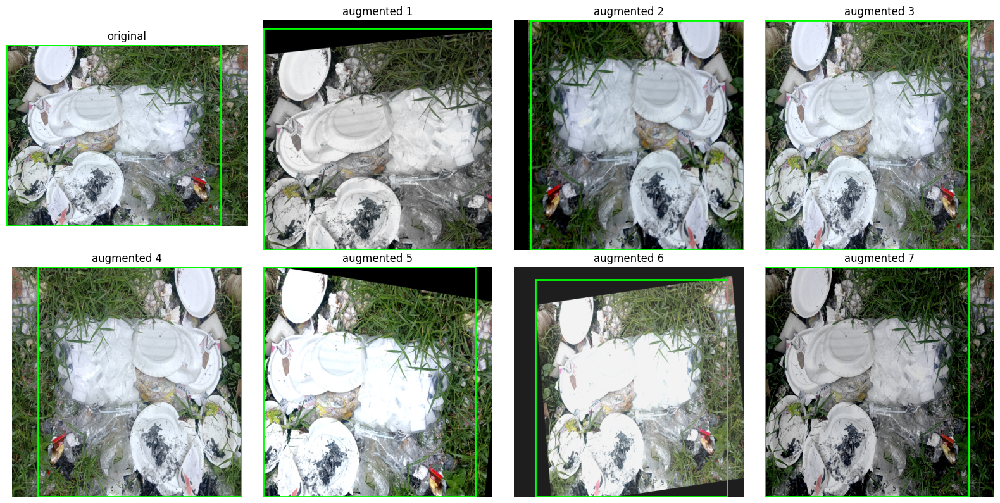

In [ ]:
def _try(ctor, name, **kw):
    try: return ctor(**kw)
    except Exception as e:
        print(f'[augmentation] "{name}" skipped (albumentations {A.__version__}): {e}'); return None

BBOX_PARAMS = A.BboxParams(format='coco', label_fields=['labels'], min_visibility=0.3, min_area=16)

def make_train_aug(S):
    t = [_try(A.HorizontalFlip, 'hflip', p=0.5),
         _try(A.BBoxSafeRandomCrop, 'box-safe crop', erosion_rate=0.0, p=0.25),
         _try(A.Affine, 'affine', scale=(0.8, 1.2), translate_percent=(-0.1, 0.1), rotate=(-8, 8), p=0.5),
         _try(A.RandomBrightnessContrast, 'brightness/contrast', brightness_limit=0.3, contrast_limit=0.3, p=0.7),
         _try(A.HueSaturationValue, 'HSV', hue_shift_limit=8, sat_shift_limit=25, val_shift_limit=20, p=0.4),
         _try(A.RandomGamma, 'gamma', gamma_limit=(70, 140), p=0.3),
         _try(A.RandomShadow, 'shadow', p=0.15),
         _try(A.GaussianBlur, 'gaussian blur', blur_limit=(3, 5), p=0.15),
         _try(A.MotionBlur, 'motion blur', blur_limit=5, p=0.1)]
    return A.Compose([x for x in t if x is not None] + [A.Resize(S, S)], bbox_params=BBOX_PARAMS)

def make_eval_tf(S): return A.Compose([A.Resize(S, S)], bbox_params=BBOX_PARAMS)

class GarbageDS(torch.utils.data.Dataset):
    """Returns a [0,1] float image (3,S,S) and normalised (cx,cy,w,h) boxes, as expected by the HF DETR-family losses."""
    def __init__(self, records, S, train=False, aug=True):
        self.r, self.S, self.train = records, S, train
        self.tf = make_train_aug(S) if (train and aug) else make_eval_tf(S)
    def __len__(self): return len(self.r)
    def __getitem__(self, i):
        r = self.r[i]; c = IMG_CACHE[r['file_name']]
        b = r['boxes'].copy(); b[:, [0, 2]] *= c['fx']; b[:, [1, 3]] *= c['fy']
        for _ in range(5 if self.train else 1):
            out = self.tf(image=c['img'], bboxes=b.tolist(), labels=[0] * len(b))
            if len(out['bboxes']) > 0 or not self.train: break
        bb = np.array([list(x[:4]) for x in out['bboxes']], dtype=np.float32).reshape(-1, 4) / self.S
        cx, cy = bb[:, 0] + bb[:, 2] / 2, bb[:, 1] + bb[:, 3] / 2
        cxcywh = np.clip(np.stack([cx, cy, bb[:, 2], bb[:, 3]], 1), 0, 1)
        img = torch.from_numpy(np.ascontiguousarray(out['image'])).permute(2, 0, 1).float() / 255
        return dict(image=img, boxes=torch.from_numpy(cxcywh), labels=torch.zeros(len(bb), dtype=torch.long), idx=i)

def collate(batch):
    return dict(image=torch.stack([b['image'] for b in batch]), boxes=[b['boxes'] for b in batch],
                labels=[b['labels'] for b in batch], idx=[b['idx'] for b in batch])

# visual check: one training image, original + 7 augmented versions (boxes must follow the pile)
ds_vis = GarbageDS(TRAIN, 640, train=True)
rec = TRAIN[0]
fig, axs = plt.subplots(2, 4, figsize=(16, 8))
c = IMG_CACHE[rec['file_name']]
axs[0, 0].imshow(c['img']); axs[0, 0].set_title('original'); axs[0, 0].axis('off')
for x1, y1, x2, y2 in xywh2xyxy(rec['boxes']):
    axs[0, 0].add_patch(plt.Rectangle((x1 * c['fx'], y1 * c['fy']), (x2 - x1) * c['fx'], (y2 - y1) * c['fy'], fill=False, ec='lime', lw=2))
for k, ax in enumerate(axs.ravel()[1:]):
    s = ds_vis[0]; im = s['image'].permute(1, 2, 0).numpy(); ax.imshow(im); ax.axis('off'); ax.set_title(f'augmented {k + 1}')
    for cx, cy, w, h in s['boxes'].numpy() * 640:
        ax.add_patch(plt.Rectangle((cx - w / 2, cy - h / 2), w, h, fill=False, ec='lime', lw=2))
plt.tight_layout(); savefig('augmentation_examples'); plt.show()

## 3. Models and a common prediction interface (Task 4)

| Model | Checkpoint (Hugging Face) | Family | Notes |
|---|---|---|---|
| DETR | `facebook/detr-resnet-50` | CNN backbone + transformer encoder-decoder, 100 object queries, Hungarian matching | Slow to converge; the original DETR needs very long schedules. |
| RT-DETR (R50-vd) | `PekingU/rtdetr_r50vd` | Hybrid encoder + IoU-aware query selection, trained with denoising queries | Built for real-time inference. |
| RT-DETR (R18-vd) | `PekingU/rtdetr_r18vd` | Same design, smaller backbone | Shows the accuracy/speed trade-off inside one family. |
| DINO | official `IDEA-Research/DINO`, 4-scale ResNet-50, 12-epoch COCO checkpoint | Deformable DETR + contrastive denoising + mixed query selection + look-forward-twice | Section 8; run as a separate process. |
| Grounding DINO (tiny) | `IDEA-Research/grounding-dino-tiny` | DINO-style detector with a text encoder; detects the phrases in a text prompt | Sections 9; zero-shot and fine-tuned. |

For the supervised models the class head is replaced by a **one-class head** (`num_labels=1`, `ignore_mismatched_sizes=True`); the rest of the network starts from the COCO weights.

**Common interface.** `Predictor` turns any of these models into "image -> boxes + scores in original-image pixels". For DETR it uses the softmax score of the object class; for RT-DETR the sigmoid score; for Grounding DINO the highest sigmoid score over the tokens of the text phrase (special tokens and the full stop are ignored). One prediction per query is kept (top 100), and **no NMS is applied** to the DETR family (they are set-prediction models). Grounding DINO optionally uses NMS (`nms_iou`), because its text-conditioned queries often produce near-duplicate boxes; that setting is recorded in the results.

In [ ]:
from transformers import (DetrForObjectDetection, RTDetrForObjectDetection,
                          AutoModelForZeroShotObjectDetection, AutoProcessor)

MODEL_ZOO = {
    'detr_r50':     dict(kind='detr',   hf='facebook/detr-resnet-50',            S=640, norm='imagenet'),
    'rtdetr_r50vd': dict(kind='rtdetr', hf='PekingU/rtdetr_r50vd',               S=640, norm=None),   # RT-DETR takes [0,1] inputs
    'rtdetr_r18vd': dict(kind='rtdetr', hf='PekingU/rtdetr_r18vd',               S=640, norm=None),
    'gdino_tiny':   dict(kind='gdino',  hf='IDEA-Research/grounding-dino-tiny',  S=800, norm='imagenet'),
}
IMNET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMNET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def build_model(zoo_name, mode='finetune', from_dir=None):
    """mode: 'finetune' -> one-class head on COCO weights; 'pretrained' -> original checkpoint unchanged."""
    spec = MODEL_ZOO[zoo_name]; kind = spec['kind']
    if from_dir is not None:
        cls = {'detr': DetrForObjectDetection, 'rtdetr': RTDetrForObjectDetection, 'gdino': AutoModelForZeroShotObjectDetection}[kind]
        return cls.from_pretrained(str(from_dir))
    kw = {} if mode == 'pretrained' else dict(num_labels=1, ignore_mismatched_sizes=True)
    if kind == 'detr':
        try:    return DetrForObjectDetection.from_pretrained(spec['hf'], revision='no_timm', **kw)
        except Exception as e:
            print('"no_timm" revision not usable, falling back to the timm backbone:', str(e)[:120])
            return DetrForObjectDetection.from_pretrained(spec['hf'], **kw)
    if kind == 'rtdetr': return RTDetrForObjectDetection.from_pretrained(spec['hf'], **kw)
    if kind == 'gdino':  return AutoModelForZeroShotObjectDetection.from_pretrained(spec['hf'])

_GDINO_PROC = {}
def gdino_tokenizer(zoo_name):
    if zoo_name not in _GDINO_PROC: _GDINO_PROC[zoo_name] = AutoProcessor.from_pretrained(MODEL_ZOO[zoo_name]['hf'])
    return _GDINO_PROC[zoo_name].tokenizer

class Predictor:
    def __init__(self, kind, model, S=640, norm='imagenet', prompt=None, tokenizer=None, agnostic=False, nms_iou=None, name='', topk=100):
        self.kind, self.model, self.S, self.norm = kind, model.to(DEVICE).eval(), S, norm
        self.agnostic, self.nms_iou, self.name, self.topk, self.tokenizer = agnostic, nms_iou, name, topk, tokenizer
        self.prompt = None
        if kind == 'gdino': self.set_prompt(prompt)

    def set_prompt(self, prompt):
        p = prompt.strip().lower(); p = p if p.endswith('.') else p + '.'      # Grounding DINO expects lower-case text ending in "."
        tok = self.tokenizer(p, return_tensors='pt'); self.prompt = p
        self.ids = {k: v.to(DEVICE) for k, v in tok.items() if k in ('input_ids', 'token_type_ids', 'attention_mask')}
        special = set(self.tokenizer.all_special_ids) | {self.tokenizer.convert_tokens_to_ids(t) for t in ('.', '?')}
        self.phrase_mask = torch.tensor([0.0 if i in special else 1.0 for i in tok['input_ids'][0].tolist()], device=DEVICE)

    def preprocess(self, img):                       # numpy RGB uint8 -> float tensor in [0,1], fixed size S x S
        x = cv2.resize(img, (self.S, self.S), interpolation=cv2.INTER_LINEAR)
        return torch.from_numpy(x).permute(2, 0, 1).float().div(255)

    def normalise(self, x):
        return (x - IMNET_MEAN.to(x.device)) / IMNET_STD.to(x.device) if self.norm == 'imagenet' else x

    def forward(self, x, labels=None):
        x = self.normalise(x); B = x.shape[0]
        if self.kind == 'gdino':
            ids = {k: v.expand(B, -1) for k, v in self.ids.items()}
            return self.model(pixel_values=x, pixel_mask=torch.ones(B, x.shape[2], x.shape[3], dtype=torch.long, device=x.device),
                              labels=labels, **ids)
        return self.model(pixel_values=x, labels=labels)

    def _scores(self, logits):
        if self.kind == 'detr':   p = logits.softmax(-1)[..., :-1]                    # last channel = "no object"
        elif self.kind == 'gdino': p = logits.sigmoid()[..., :self.phrase_mask.numel()] * self.phrase_mask.view(1, 1, -1)
        else:                     p = logits.sigmoid()                                # RT-DETR
        return p.max(-1).values                                                       # one-class model: the only class; agnostic baseline: best COCO class

    @torch.no_grad()
    def postprocess(self, out, wh_list):
        scores = self._scores(out.logits.float()); cx, cy, w, h = out.pred_boxes.float().unbind(-1)
        xyxy = torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1).clamp(0, 1)
        res = []
        for b in range(scores.shape[0]):
            W, H = wh_list[b]; s, idx = scores[b].topk(min(self.topk, scores.shape[1]))
            bx = xyxy[b][idx] * torch.tensor([W, H, W, H], device=xyxy.device)
            if self.nms_iou:
                keep = torchvision.ops.nms(bx, s, self.nms_iou); bx, s = bx[keep], s[keep]
            res.append(dict(boxes=bx.cpu().numpy().astype(np.float32), scores=s.cpu().numpy().astype(np.float32)))
        return res

    @torch.no_grad()
    def predict_records(self, records, bs=4, amp=False, desc=None):
        self.model.eval(); preds = {}
        for i in tqdm(range(0, len(records), bs), desc=desc or self.name, leave=False):
            chunk = records[i:i + bs]
            x = torch.stack([self.preprocess(IMG_CACHE[r['file_name']]['img']) for r in chunk]).to(DEVICE)
            with torch.autocast('cuda', dtype=torch.float16, enabled=amp): out = self.forward(x)
            for r, d in zip(chunk, self.postprocess(out, [(r['W'], r['H']) for r in chunk])): preds[r['file_name']] = d
        return preds

## 4. Evaluation metrics (Task 5)

All models are scored by the **same functions** on the **same held-out test images**.

* **mAP@0.5 and mAP@0.5:0.95** with the official COCO evaluator (`pycocotools`), using up to 100 detections per image with confidence >= 0.001. With one class, this is simply the AP of the class. COCO's small/medium/large breakdown is not reported, because with the original photo sizes almost all piles are "large".
* **Precision, recall, F1** at a confidence threshold: a prediction is a true positive if its IoU with a still-unmatched ground-truth box is >= 0.5 (greedy matching by score). Precision = TP / (TP + FP), recall = TP / (TP + FN). Two thresholds are reported:
  * the **tuned threshold**, chosen as the value that maximises F1 on the **validation** set (never on the test set), and
  * a **fixed threshold of 0.5**.
* **Bootstrap 95 % intervals** for precision, recall and F1 (1000 resamples of the test images). They show how uncertain a small test set is.
* **Inference speed and latency** (Section 4.1): measured with batch size 1, GPU-synchronised timers after warm-up.

In [ ]:
def iou_matrix(a, b):
    a, b = np.asarray(a, float).reshape(-1, 4), np.asarray(b, float).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area = lambda z: (z[:, 2] - z[:, 0]) * (z[:, 3] - z[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)

def match_image(pb, gb, thr=IOU_MATCH):
    """pb sorted by descending score. Returns tp, fp, fn and the mean (over GT boxes) of the best IoU with any prediction."""
    n_g = len(gb)
    if len(pb) == 0: return 0, 0, n_g, 0.0
    if n_g == 0:     return 0, len(pb), 0, 0.0
    iou = iou_matrix(pb, gb); used = np.zeros(n_g, bool); tp = 0
    for i in range(len(pb)):
        j = int(np.argmax(np.where(used, -1, iou[i])))
        if (not used[j]) and iou[i, j] >= thr: used[j] = True; tp += 1
    return tp, len(pb) - tp, n_g - tp, float(iou.max(0).mean())

def prf_at(preds, records, thr):
    rows = []
    for r in records:
        d = preds[r['file_name']]; keep = d['scores'] >= thr
        pb, ps = d['boxes'][keep], d['scores'][keep]; pb = pb[np.argsort(-ps)]
        tp, fp, fn, best = match_image(pb, xywh2xyxy(r['boxes']))
        rows.append(dict(file_name=r['file_name'], tp=tp, fp=fp, fn=fn, best_iou=best, n_pred=len(pb), n_gt=len(r['boxes'])))
    df = pd.DataFrame(rows); TP, FP, FN = df.tp.sum(), df.fp.sum(), df.fn.sum()
    P = TP / (TP + FP) if TP + FP else 0.0; R = TP / (TP + FN) if TP + FN else 0.0
    return dict(precision=P, recall=R, f1=2 * P * R / (P + R) if P + R else 0.0, TP=int(TP), FP=int(FP), FN=int(FN), per_image=df)

def tune_threshold(preds, records, grid=np.arange(0.05, 0.96, 0.01)):
    best_t, best_f = 0.5, -1
    for t in grid:
        f = prf_at(preds, records, t)['f1']
        if f >= best_f: best_t, best_f = float(t), f                 # ties -> the higher threshold
    return round(best_t, 2), best_f

def pr_curve(preds, records, grid=np.linspace(0.02, 0.98, 25)):
    pts = [prf_at(preds, records, t) for t in grid]
    return dict(thr=grid, precision=np.array([p['precision'] for p in pts]), recall=np.array([p['recall'] for p in pts]),
                f1=np.array([p['f1'] for p in pts]))

def bootstrap_prf(per_image, n=1000, seed=0):
    rng = np.random.default_rng(seed); tp, fp, fn = (per_image[c].values for c in ('tp', 'fp', 'fn')); out = []
    for _ in range(n):
        i = rng.integers(0, len(tp), len(tp)); T, F, N = tp[i].sum(), fp[i].sum(), fn[i].sum()
        P = T / (T + F) if T + F else 0.0; R = T / (T + N) if T + N else 0.0
        out.append((P, R, 2 * P * R / (P + R) if P + R else 0.0))
    lo, hi = np.percentile(out, [2.5, 97.5], axis=0)
    return dict(precision=(lo[0], hi[0]), recall=(lo[1], hi[1]), f1=(lo[2], hi[2]))

def to_coco_results(preds, records, min_score=0.001):
    res = []
    for r in records:
        d = preds[r['file_name']]
        for b, s in zip(d['boxes'], d['scores']):
            if s >= min_score:
                res.append(dict(image_id=r['image_id'], category_id=CAT_ID, score=float(s),
                                bbox=[float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])]))
    return res

def coco_metrics(split, preds):
    recs = SPLITS[split]; res = to_coco_results(preds, recs)
    if not res or not GT[split]['annotations']: return dict(AP=0.0, AP50=0.0, AP75=0.0, AR100=0.0)
    gt = COCO(); gt.dataset = copy.deepcopy(GT[split])
    with contextlib.redirect_stdout(io.StringIO()):
        gt.createIndex(); dt = gt.loadRes(res)
        E = COCOeval(gt, dt, 'bbox'); E.params.imgIds = [r['image_id'] for r in recs]
        E.evaluate(); E.accumulate(); E.summarize()
    f = lambda v: float(max(v, 0.0)); s = E.stats
    return dict(AP=f(s[0]), AP50=f(s[1]), AP75=f(s[2]), AR100=f(s[8]))

# --- self-test of the metric code on a toy example (must print 1.0 / 0.5 style values) -----------
_toy = [dict(file_name='a', boxes=np.array([[10, 10, 50, 50]], float)), dict(file_name='b', boxes=np.array([[0, 0, 40, 40]], float))]
_pred = {'a': dict(boxes=np.array([[10, 10, 60, 60], [200, 200, 220, 220]], np.float32), scores=np.array([0.9, 0.8], np.float32)),
         'b': dict(boxes=np.zeros((0, 4), np.float32), scores=np.zeros(0, np.float32))}
_r = prf_at(_pred, _toy, 0.5)
print('toy check -> TP/FP/FN =', _r['TP'], _r['FP'], _r['FN'], '(expected 1 1 1)  precision', _r['precision'], 'recall', _r['recall'])

toy check -> TP/FP/FN = 1 1 1 (expected 1 1 1)  precision 0.5 recall 0.5


### 4.1 Speed, latency, size

* **Latency** is the time to process one image and return detections, with batch size 1. Two numbers are given: *model* (network forward only) and *end-to-end* (resize and tensor conversion, forward, post-processing).
* **FPS** = 1000 / mean end-to-end latency (ms).
* Measured at full precision (FP32) and with FP16 autocast, after 5 warm-up images, over 40 images from the test set.
* **Peak GPU memory** is the maximum allocated while running these 40 images (weights included).
* Parameters are counted over the whole model. FLOPs are not measured.

In [ ]:
def measure_latency(P, records, n=40, warmup=5):
    imgs = [(IMG_CACHE[r['file_name']]['img'], (r['W'], r['H'])) for r in records]; out = {}
    out['params_M'] = sum(p.numel() for p in P.model.parameters()) / 1e6
    for tag, amp in (('fp32', False), ('fp16', True)):
        t_model, t_e2e = [], []; torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        for i in range(warmup + n):
            img, wh = imgs[i % len(imgs)]
            torch.cuda.synchronize(); t0 = perf_counter()
            x = P.preprocess(img)[None].to(DEVICE)
            torch.cuda.synchronize(); t1 = perf_counter()
            with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16, enabled=amp): o = P.forward(x)
            torch.cuda.synchronize(); t2 = perf_counter()
            P.postprocess(o, [wh]); torch.cuda.synchronize(); t3 = perf_counter()
            if i >= warmup: t_model.append((t2 - t1) * 1e3); t_e2e.append((t3 - t0) * 1e3)
        out.update({f'lat_model_ms_{tag}': float(np.mean(t_model)), f'lat_e2e_ms_{tag}': float(np.mean(t_e2e)),
                    f'lat_e2e_p95_ms_{tag}': float(np.percentile(t_e2e, 95)), f'fps_{tag}': float(1000 / np.mean(t_e2e)),
                    f'peak_mem_MB_{tag}': torch.cuda.max_memory_allocated() / 2**20})
    return out

RESULTS = {}     # tag -> dict(row=..., preds_test=..., per_image=..., pr=..., ci=...)

def evaluate_preds(tag, group, pv, pt, speed=None, extra=None, thr=None):
    """Compute every metric of Task 5 from val/test predictions and store everything in RESULTS.
    `speed` is the dict returned by measure_latency (or by the DINO inference script)."""
    thr_star, f1_val = tune_threshold(pv, VAL) if thr is None else (thr, float('nan'))
    mt, mv = coco_metrics('test', pt), coco_metrics('val', pv)
    a, b = prf_at(pt, TEST, thr_star), prf_at(pt, TEST, CONF_FIXED)
    row = dict(tag=tag, group=group, thr=thr_star, test_AP=mt['AP'], test_AP50=mt['AP50'], test_AP75=mt['AP75'], test_AR100=mt['AR100'],
               precision=a['precision'], recall=a['recall'], f1=a['f1'], TP=a['TP'], FP=a['FP'], FN=a['FN'],
               precision_at_0_5=b['precision'], recall_at_0_5=b['recall'], f1_at_0_5=b['f1'],
               val_AP=mv['AP'], val_AP50=mv['AP50'], val_f1=f1_val)
    if speed: row.update(speed)
    if extra: row.update(extra)
    RESULTS[tag] = dict(row=row, preds_test=pt, preds_val=pv, per_image=a['per_image'], pr=pr_curve(pt, TEST), ci=bootstrap_prf(a['per_image']))
    (OUT / 'results_rows').mkdir(exist_ok=True)
    safe = re.sub(r'[^A-Za-z0-9_.-]+', '_', tag)[:80]
    with open(OUT / 'results_rows' / f'{safe}.json', 'w') as f: json.dump(row, f, indent=1, default=float)
    print(f"{tag:44s} test AP50 {mt['AP50']:.3f} | AP {mt['AP']:.3f} | P {a['precision']:.3f} R {a['recall']:.3f} (thr {thr_star})"
          + (f" | {row['fps_fp32']:.1f} FPS fp32" if 'fps_fp32' in row else ''))
    return RESULTS[tag]

def evaluate_predictor(P, tag, group, extra=None, speed=True, thr=None):
    pv = P.predict_records(VAL, desc=f'{tag} val'); pt = P.predict_records(TEST, desc=f'{tag} test')
    return evaluate_preds(tag, group, pv, pt, speed=measure_latency(P, TEST) if speed else None, extra=extra, thr=thr)

## 5. Training engine (Task 4)

One training loop serves DETR, RT-DETR and Grounding DINO (Hugging Face models compute their own set-prediction loss from `labels`).

* **Optimiser:** AdamW, a lower learning rate for the backbone (`lr_backbone`) than for the transformer and heads, gradient clipping, linear warm-up for one epoch, then cosine decay to 5 % of the learning rate.
* **Model selection:** after every `eval_every` epochs the model is evaluated on the **validation** set; the checkpoint with the highest `AP50 + AP` is kept, and training stops early if it does not improve for `patience` evaluations. The test set is never used for any choice.
* **Logged for the report:** training loss, validation loss, validation AP50 and AP per epoch, seconds per epoch, total training time, peak GPU memory.
* Mixed precision is **off** by default because the Hungarian matcher in these implementations can misbehave in FP16; switch `amp=True` only if memory is short.
* Hyperparameters live in `EXPERIMENTS` below, which doubles as the configuration table for the report. They are reasonable defaults for ~100 training images, **not** tuned values; the notebook includes small studies (augmentation on/off, learning rate, backbone size) to show how the configuration matters.

In [ ]:
def forward_with_loss(P, batch):
    x = batch['image'].to(DEVICE)
    labels = [dict(class_labels=l.to(DEVICE), boxes=b.to(DEVICE)) for l, b in zip(batch['labels'], batch['boxes'])]
    return P.forward(x, labels=labels)

@torch.no_grad()
def compute_val_loss(P, loader):
    P.model.eval(); tot, n = 0.0, 0
    try:
        for batch in loader:
            tot += float(forward_with_loss(P, batch).loss) * len(batch['idx']); n += len(batch['idx'])
        return tot / max(n, 1)
    except Exception as e:
        print('  (validation loss unavailable for this model:', str(e)[:100], ')'); return float('nan')

def fit(tag, exp):
    mz = MODEL_ZOO[exp['model']]; kind = mz['kind']; seed_everything(SEED)
    model = build_model(exp['model'], mode='finetune').to(DEVICE)
    tok = gdino_tokenizer(exp['model']) if kind == 'gdino' else None
    P = Predictor(kind, model, S=mz['S'], norm=mz['norm'], prompt=exp.get('prompt'), tokenizer=tok, nms_iou=exp.get('nms'), name=tag)
    for pat in exp.get('freeze', []):
        for n_, p_ in model.named_parameters():
            if pat in n_: p_.requires_grad = False
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    n_all = sum(p.numel() for p in model.parameters()) / 1e6

    g = torch.Generator(); g.manual_seed(SEED)
    tl = torch.utils.data.DataLoader(GarbageDS(TRAIN, mz['S'], train=True, aug=exp['aug']), batch_size=exp['bs'], shuffle=True,
                                     num_workers=2, collate_fn=collate, drop_last=False, generator=g)
    vl = torch.utils.data.DataLoader(GarbageDS(VAL, mz['S'], train=False), batch_size=exp['bs'], shuffle=False, num_workers=2, collate_fn=collate)
    bb = [p for n_, p in model.named_parameters() if p.requires_grad and 'backbone' in n_]
    rest = [p for n_, p in model.named_parameters() if p.requires_grad and 'backbone' not in n_]
    groups = ([dict(params=rest, lr=exp['lr'])] if rest else []) + ([dict(params=bb, lr=exp['lr_backbone'])] if bb else [])
    opt = torch.optim.AdamW(groups, weight_decay=exp['wd'])
    epochs = 2 if QUICK_TEST else exp['epochs']; accum = exp.get('accum', 1)
    spe = math.ceil(len(tl) / accum); total, warm = epochs * spe, spe
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / warm) * (0.05 + 0.95 * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total)))))
    scaler = torch.amp.GradScaler('cuda', enabled=exp.get('amp', False))

    ckpt_dir = OUT / tag / 'best'; ckpt_dir.parent.mkdir(parents=True, exist_ok=True)
    hist, best, bad, nan_steps = [], -1.0, 0, 0; torch.cuda.reset_peak_memory_stats(); t_start = perf_counter()
    print(f'\n=== {tag}: {exp["model"]} | {n_train:.1f}M trainable of {n_all:.1f}M params | {len(TRAIN)} train / {len(VAL)} val images | {epochs} epochs ===')
    for ep in range(1, epochs + 1):
        model.train(); t0 = perf_counter(); run, cnt = 0.0, 0; opt.zero_grad(set_to_none=True)
        for i, batch in enumerate(tl):
            with torch.autocast('cuda', dtype=torch.float16, enabled=exp.get('amp', False)):
                loss = forward_with_loss(P, batch).loss / accum
            if not torch.isfinite(loss): nan_steps += 1; opt.zero_grad(set_to_none=True); continue
            scaler.scale(loss).backward(); run += float(loss) * accum; cnt += 1
            if (i + 1) % accum == 0 or i + 1 == len(tl):
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), exp['clip'])
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
        row = dict(epoch=ep, train_loss=run / max(cnt, 1), lr=opt.param_groups[0]['lr'], epoch_time_s=perf_counter() - t0)
        if ep % exp.get('eval_every', 1) == 0 or ep == epochs:
            row['val_loss'] = compute_val_loss(P, vl)
            m = coco_metrics('val', P.predict_records(VAL)); row.update(val_AP50=m['AP50'], val_AP=m['AP'])
            sel = m['AP50'] + m['AP']
            if sel > best: best, bad = sel, 0; model.save_pretrained(ckpt_dir); row['best'] = True
            else: bad += 1
        hist.append(row)
        if 'val_AP50' in row: print(f"  ep {ep:3d} | train loss {row['train_loss']:.3f} | val loss {row['val_loss']:.3f} | val AP50 {row['val_AP50']:.3f} | AP {row['val_AP']:.3f} | {row['epoch_time_s']:.0f}s" + (' *' if row.get('best') else ''))
        if bad >= exp['patience']: print(f'  early stop at epoch {ep}'); break
    H = pd.DataFrame(hist); H.to_csv(OUT / tag / 'history.csv', index=False)
    summary = dict(tag=tag, **{k: v for k, v in exp.items()}, epochs_run=len(H), best_epoch=int(H.loc[H.get('best', False) == True, 'epoch'].max()) if 'best' in H else None,
                   train_time_min=(perf_counter() - t_start) / 60, train_peak_mem_MB=torch.cuda.max_memory_allocated() / 2**20,
                   mean_epoch_time_s=float(H.epoch_time_s.mean()), trainable_params_M=n_train, total_params_M=n_all, nan_steps=nan_steps,
                   gpu=GPU_NAME, torch=torch.__version__, transformers=transformers.__version__)
    with open(OUT / tag / 'train_summary.json', 'w') as f: json.dump(summary, f, indent=1, default=str)
    del P, model, opt; gc.collect(); torch.cuda.empty_cache()
    return H, summary

def plot_curves(tags, fname):
    fig, axs = plt.subplots(1, 3, figsize=(17, 4))
    for t in tags:
        p = OUT / t / 'history.csv'
        if not p.exists(): continue
        H = pd.read_csv(p); axs[0].plot(H.epoch, H.train_loss, label=t)
        v = H.dropna(subset=['val_AP50']); axs[1].plot(v.epoch, v.val_loss, label=t); axs[2].plot(v.epoch, v.val_AP50, label=t)
    for a, ttl in zip(axs, ['training loss', 'validation loss', 'validation AP@0.5']): a.set_title(ttl); a.set_xlabel('epoch'); a.grid(alpha=.3)
    axs[2].legend(fontsize=8); plt.tight_layout(); savefig(fname); plt.show()

## 6. Fine-tuning experiments: DETR and RT-DETR (Task 4)

The table below is the training-configuration record. Experiments in this section:

| Tag | Purpose |
|---|---|
| `detr_r50` | DETR baseline. Longer schedule because DETR converges slowly. |
| `rtdetr_r50vd` | Main RT-DETR run. |
| `rtdetr_r18vd` | Smaller RT-DETR: accuracy versus speed inside one family. |
| `rtdetr_r50vd_noaug` | Same as `rtdetr_r50vd` but with **no augmentation**: what does augmentation add? |
| `rtdetr_r50vd_lr5e5` | Same as `rtdetr_r50vd` with half the learning rate: sensitivity to the training configuration. |

Edit `RUN` to run only some of them. With `QUICK_TEST = True` every run lasts two epochs.

,model,epochs,bs,lr,lr_backbone,wd,clip,aug,patience
detr_r50,detr_r50,80,4,0.0001,0.00001,0.0001,0.1,True,10
rtdetr_r50vd,rtdetr_r50vd,60,4,0.0001,0.00001,0.0001,0.1,True,12
rtdetr_r18vd,rtdetr_r18vd,60,4,0.0001,0.00001,0.0001,0.1,True,12
rtdetr_r50vd_noaug,rtdetr_r50vd,60,4,0.0001,0.00001,0.0001,0.1,False,12
rtdetr_r50vd_lr5e5,rtdetr_r50vd,60,4,0.00005,0.000005,0.0001,0.1,True,12


detr_r50: a trained checkpoint already exists in Drive, skipping training (delete /content/drive/MyDrive/Ru_Garbase/Experiments/detr_r50 to retrain).
rtdetr_r50vd: a trained checkpoint already exists in Drive, skipping training (delete /content/drive/MyDrive/Ru_Garbase/Experiments/rtdetr_r50vd to retrain).
rtdetr_r18vd: a trained checkpoint already exists in Drive, skipping training (delete /content/drive/MyDrive/Ru_Garbase/Experiments/rtdetr_r18vd to retrain).
rtdetr_r50vd_noaug: a trained checkpoint already exists in Drive, skipping training (delete /content/drive/MyDrive/Ru_Garbase/Experiments/rtdetr_r50vd_noaug to retrain).
rtdetr_r50vd_lr5e5: a trained checkpoint already exists in Drive, skipping training (delete /content/drive/MyDrive/Ru_Garbase/Experiments/rtdetr_r50vd_lr5e5 to retrain).


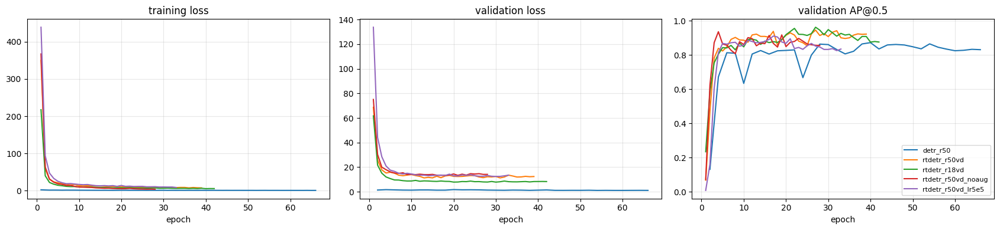

In [ ]:
BASE = dict(bs=4, lr=1e-4, lr_backbone=1e-5, wd=1e-4, clip=0.1, aug=True, amp=False, eval_every=1, patience=12)
EXPERIMENTS = {
    'detr_r50':            dict(BASE, model='detr_r50',     epochs=80, eval_every=2, patience=10),
    'rtdetr_r50vd':        dict(BASE, model='rtdetr_r50vd', epochs=60),
    'rtdetr_r18vd':        dict(BASE, model='rtdetr_r18vd', epochs=60),
    'rtdetr_r50vd_noaug':  dict(BASE, model='rtdetr_r50vd', epochs=60, aug=False),
    'rtdetr_r50vd_lr5e5':  dict(BASE, model='rtdetr_r50vd', epochs=60, lr=5e-5, lr_backbone=5e-6),
}
RUN = ['detr_r50', 'rtdetr_r50vd', 'rtdetr_r18vd', 'rtdetr_r50vd_noaug', 'rtdetr_r50vd_lr5e5']

display(pd.DataFrame(EXPERIMENTS).T[['model', 'epochs', 'bs', 'lr', 'lr_backbone', 'wd', 'clip', 'aug', 'patience']])
TRAIN_SUMMARY = {}
for tag in RUN:
    if (OUT / tag / 'best' / 'config.json').exists() and not QUICK_TEST:
        print(f'{tag}: a trained checkpoint already exists in Drive, skipping training (delete {OUT / tag} to retrain).'); continue
    try:
        H, TRAIN_SUMMARY[tag] = fit(tag, EXPERIMENTS[tag])
    except Exception as e:
        print(f'!! {tag} failed: {type(e).__name__}: {e}'); gc.collect(); torch.cuda.empty_cache()
plot_curves([t for t in RUN], 'training_curves_detr_rtdetr')

## 7. Quantitative results (Tasks 5 and 6)

### 7.1 Original pretrained models, before fine-tuning

DETR and RT-DETR were trained on COCO, which has **no "garbage" class**, so their original versions cannot be asked for piled garbage. To still obtain a "before fine-tuning" number on the same test set, the original model is run unchanged and **every detection of any COCO class is accepted as a garbage candidate** (class-agnostic evaluation, best class score per query). Read the result as: *how often does a COCO detector happen to put a confident box on a garbage pile?* It is a lower bound, and the gap to the fine-tuned model measures what fine-tuning adds. The same is done for the official DINO checkpoint in Section 8. Grounding DINO is different: its original model **can** be prompted with text, so its zero-shot result is a meaningful baseline (Section 9).

The confidence threshold for precision/recall is tuned on the validation set for every model, pretrained ones included.

In [ ]:
for name in ['detr_r50', 'rtdetr_r50vd', 'rtdetr_r18vd']:
    mz = MODEL_ZOO[name]
    try:
        m = build_model(name, mode='pretrained')
        P = Predictor(mz['kind'], m, S=mz['S'], norm=mz['norm'], agnostic=True, name=f'{name}_pretrained')
        evaluate_predictor(P, f'{name}::pretrained (class-agnostic)', 'pretrained', extra=dict(model=name))
        del P, m
    except Exception as e: print(f'!! pretrained baseline {name} failed: {type(e).__name__}: {e}')
    gc.collect(); torch.cuda.empty_cache()

config.json:   0%|          | 0.00/6.60k [00:00<?, ?B/s]

"no_timm" revision not usable, falling back to the timm backbone: Validation error for field 'dilation':
    TypeError: Field 'dilation' expected bool, got NoneType (value: None)


config.json:   0%|          | 0.00/4.59k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  167MB            

model.safetensors: downloading bytes:           |  0.00B            

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/526 [00:00<?, ?it/s]

rtdetr_r18vd::pretrained (class-agnostic) val:   0%|          | 0/7 [00:00<?, ?it/s]

rtdetr_r18vd::pretrained (class-agnostic) test:   0%|          | 0/6 [00:00<?, ?it/s]

rtdetr_r18vd::pretrained (class-agnostic)    test AP50 0.071 | AP 0.036 | P 0.052 R 0.250 (thr 0.22) | 27.0 FPS fp32


### 7.2 Fine-tuned models

In [ ]:
for tag in RUN:
    d = OUT / tag / 'best'
    if not (d / 'config.json').exists(): print(f'{tag}: no trained checkpoint found, skipping'); continue
    exp = EXPERIMENTS[tag]; mz = MODEL_ZOO[exp['model']]
    m = build_model(exp['model'], from_dir=d)
    P = Predictor(mz['kind'], m, S=mz['S'], norm=mz['norm'], name=tag)
    summ = json.load(open(OUT / tag / 'train_summary.json')) if (OUT / tag / 'train_summary.json').exists() else {}
    evaluate_predictor(P, tag, 'fine-tuned', extra=dict(model=exp['model'], train_time_min=summ.get('train_time_min'),
                       epochs_run=summ.get('epochs_run'), best_epoch=summ.get('best_epoch'), mean_epoch_time_s=summ.get('mean_epoch_time_s'),
                       train_peak_mem_MB=summ.get('train_peak_mem_MB')))
    del P, m; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

detr_r50 val:   0%|          | 0/7 [00:00<?, ?it/s]

detr_r50 test:   0%|          | 0/6 [00:00<?, ?it/s]

detr_r50                                     test AP50 0.890 | AP 0.582 | P 1.000 R 0.708 (thr 0.9) | 21.1 FPS fp32


Loading weights:   0%|          | 0/764 [00:00<?, ?it/s]

...

rtdetr_r50vd_noaug                           test AP50 0.885 | AP 0.635 | P 0.588 R 0.833 (thr 0.26) | 13.7 FPS fp32


Loading weights:   0%|          | 0/764 [00:00<?, ?it/s]

rtdetr_r50vd_lr5e5 val:   0%|          | 0/7 [00:00<?, ?it/s]

rtdetr_r50vd_lr5e5 test:   0%|          | 0/6 [00:00<?, ?it/s]

rtdetr_r50vd_lr5e5                           test AP50 0.889 | AP 0.640 | P 0.944 R 0.708 (thr 0.82) | 13.5 FPS fp32


## 8. DINO (DETR with Improved DeNoising Anchor Boxes), official implementation (Task 4)

`transformers` does not contain DINO-DETR, so this section uses the **official IDEA-Research code**, fine-tuned from the released COCO checkpoint (ResNet-50, 4 scales, 12 epochs, about 49 AP on COCO according to the repository). What the code does:

1. clones the repository and applies small compatibility patches (the repository was written for PyTorch 1.9; see below);
2. writes your splits in the COCO folder layout the repository expects (`train2017`, `val2017`, `annotations/instances_*.json`; images are the cached versions with the long side <= 1024 px);
3. fine-tunes with the repository's own `main.py` (one class; the class head and label encoder are re-initialised: `--finetune_ignore label_enc.weight class_embed`);
4. runs inference with a helper script inside the repository's environment (to avoid a name clash between its `datasets` package and Hugging Face `datasets`), writes the predictions to a JSON file, and evaluates them with the **same metric code as every other model**.

**Manual step (once):** download `checkpoint0011_4scale.pth` from the DINO model zoo (the Google Drive folder linked in the README of https://github.com/IDEA-Research/DINO) and place it at `Ru_Garbase/Pretrained/checkpoint0011_4scale.pth` in your Drive. The notebook cannot fetch it reliably because the folder is large and contains many other checkpoints.

**Differences from the other detectors, to state in the report:** DINO keeps its own aspect-preserving resize (short side 800, long side <= 1333) and its own built-in augmentation (flip, multi-scale resize, random crop) instead of the albumentations pipeline of Section 2; it uses deformable attention, which here runs in **pure PyTorch** (slower and more memory-hungry than the CUDA kernel, but it avoids compiling the extension on a modern PyTorch). Set `DINO_USE_CUDA_OPS = True` to try the compiled version first.

If this section fails, set `RUN_DINO_OFFICIAL = False`; the remaining sections do not depend on it, and Grounding DINO (Section 9) is a DINO-family detector that can stand in for the comparison.

In [ ]:
RUN_DINO_OFFICIAL = True
DINO_USE_CUDA_OPS = False
DINO_DIR        = Path('/content/DINO')
DINO_PRETRAINED = ROOT / 'Pretrained' / 'checkpoint0011_4scale.pth'
DINO_TAG        = 'dino_r50_4scale'
DINO_EPOCHS, DINO_LR_DROP, DINO_BS = 20, 15, 2
DINO_DATA       = Path('/content/dino_coco')
DINO_LOCAL_RUN  = Path('/content/dino_runs') / DINO_TAG
DINO_OK = False
ENV = dict(os.environ, TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD='1', PYTHONUNBUFFERED='1')

def sh(cmd, cwd=None, tail=2500, show=True):
    r = subprocess.run(cmd, shell=True, cwd=cwd, capture_output=True, text=True, env=ENV)
    if show and (r.stdout or r.stderr): print((r.stdout + r.stderr)[-tail:])
    return r.returncode

def run_stream(cmd, cwd, logfile, keep=('Averaged stats', 'Training time', 'Traceback', 'Error', 'error:', 'IoU=0.50 ', 'IoU=0.50:0.95 | area=   all')):
    """Run a long command, write everything to `logfile` and print only the important lines."""
    last = []
    with open(logfile, 'w') as lf:
        p = subprocess.Popen(cmd, shell=True, cwd=cwd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=ENV)
        for line in p.stdout:
            lf.write(line); last.append(line); last = last[-40:]
            if any(k in line for k in keep): print(line.rstrip()[:220])
        p.wait()
    if p.returncode != 0: print('--- last lines of the log ---\n' + ''.join(last[-25:]))
    return p.returncode

if RUN_DINO_OFFICIAL:
    (ROOT / 'Pretrained').mkdir(exist_ok=True)
    if not DINO_PRETRAINED.exists():
        print('Checkpoint not found at', DINO_PRETRAINED, '\n-> download checkpoint0011_4scale.pth from the model zoo linked in the DINO README and put it there, then re-run this cell.')
    else:
        if not DINO_DIR.exists(): sh(f'git clone --depth 1 https://github.com/IDEA-Research/DINO.git {DINO_DIR}', show=False)
        sh('pip -q install addict yapf termcolor pycocotools', show=False)
        print('DINO repository ready:', DINO_DIR.exists())

Checkpoint not found at /content/drive/MyDrive/Ru_Garbase/Pretrained/checkpoint0011_4scale.pth 
-> download checkpoint0011_4scale.pth from the model zoo linked in the DINO README and put it there, then re-run this cell.


### 8.1 Compatibility patches for the DINO repository

The repository targets PyTorch 1.9. The patches below are small text substitutions (each one is reported):

* the DETR-era check `float(torchvision.__version__[:3]) < 0.7`, which misfires on modern torchvision versions;
* `from torch._six import inf` (module removed from PyTorch);
* `np.float`, `np.int`, `np.bool` (removed from NumPy);
* a **pure-PyTorch fallback for multi-scale deformable attention**, used when the compiled CUDA extension is not available;
* `torch.load` defaulting to `weights_only=True` in recent PyTorch is handled by an environment variable for the training run (the helper script passes `weights_only=False` itself).

In [ ]:
def patch_dino():
    log = Counter()
    for p in DINO_DIR.rglob('*.py'):
        if '/ops/src' in str(p) or p.name == 'setup.py': continue
        s = o = p.read_text()
        s, n1 = re.subn(r'float\(torchvision\.__version__\[:3\]\)\s*<\s*0\.7', 'False', s)
        s, n2 = re.subn(r'from torch\._six import inf', 'from math import inf', s)
        s, n3 = re.subn(r'\bnp\.(float|int|bool)\b(?![\w])', r'\1', s)
        if s != o: p.write_text(s); log['torchvision-check'] += n1; log['torch._six'] += n2; log['numpy aliases'] += n3
    fn = DINO_DIR / 'models/dino/ops/functions/ms_deform_attn_func.py'
    if fn.exists():
        s = fn.read_text()
        if 'MSDA_FALLBACK' in s: log['msda fallback (already applied)'] += 1
        elif 'import MultiScaleDeformableAttention as MSDA' in s:
            s = s.replace('import MultiScaleDeformableAttention as MSDA',
                          'try:\n    import MultiScaleDeformableAttention as MSDA\nexcept ImportError:\n    MSDA = None')
            s += '''

# MSDA_FALLBACK: pure-PyTorch deformable attention, used when the CUDA extension is not built
if MSDA is None:
    class MSDeformAttnFunction:
        @staticmethod
        def apply(value, value_spatial_shapes, value_level_start_index, sampling_locations, attention_weights, im2col_step):
            return ms_deform_attn_core_pytorch(value, value_spatial_shapes, sampling_locations, attention_weights)
'''
            fn.write_text(s); log['msda fallback'] += 1
        else: print('WARNING: could not find the MSDA import line; the fallback patch was NOT applied')
    else: print('WARNING: ms_deform_attn_func.py not found at', fn)
    print('patches applied:', dict(log))

if RUN_DINO_OFFICIAL and DINO_DIR.exists():
    if DINO_USE_CUDA_OPS:
        rc = sh('python setup.py build install', cwd=DINO_DIR / 'models/dino/ops', tail=1500, show=False)
        ok = sh('python -c "import MultiScaleDeformableAttention"', show=False) == 0
        print('CUDA extension built and importable:', ok)
    patch_dino()

### 8.2 Write the data in the layout expected by DINO, fine-tune, and evaluate

In [ ]:
def export_for_dino():
    (DINO_DATA / 'annotations').mkdir(parents=True, exist_ok=True); manifest = []
    for s in ('train', 'val', 'test'):
        (DINO_DATA / f'{s}2017').mkdir(exist_ok=True); images, anns, k = [], [], 1
        for r in SPLITS[s]:
            c = IMG_CACHE[r['file_name']]; h, w = c['img'].shape[:2]; dst = DINO_DATA / f'{s}2017' / r['file_name']
            if not dst.exists(): cv2.imwrite(str(dst), c['img'][..., ::-1], [cv2.IMWRITE_JPEG_QUALITY, 95])
            images.append(dict(id=r['image_id'], file_name=r['file_name'], width=w, height=h))
            for x, y, bw, bh in r['boxes']:
                bx = [x * c['fx'], y * c['fy'], bw * c['fx'], bh * c['fy']]
                anns.append(dict(id=k, image_id=r['image_id'], category_id=CAT_ID, bbox=bx, area=bx[2] * bx[3], iscrowd=0)); k += 1
            manifest.append(dict(split=s, file_name=r['file_name'], path=str(dst), W=r['W'], H=r['H']))
        json.dump(dict(images=images, annotations=anns, categories=[dict(id=CAT_ID, name=CAT_NAME)]),
                  open(DINO_DATA / 'annotations' / f'instances_{s}2017.json', 'w'))
    json.dump(manifest, open(DINO_DATA / 'manifest.json', 'w'))
    print('DINO data written to', DINO_DATA, '|', {s: len(SPLITS[s]) for s in SPLITS})

def parse_dino_log(path):
    rows = []
    for line in open(path):
        try: d = json.loads(line)
        except Exception: continue
        if 'epoch' not in d: continue
        ap = d.get('test_coco_eval_bbox', [np.nan, np.nan])
        rows.append(dict(epoch=d['epoch'] + 1, train_loss=d.get('train_loss', np.nan), val_loss=d.get('test_loss', np.nan),
                         val_AP50=ap[1], val_AP=ap[0]))
    return pd.DataFrame(rows)

DINO_SUMMARY = {}
if RUN_DINO_OFFICIAL and DINO_PRETRAINED.exists() and DINO_DIR.exists():
    export_for_dino()
    drive_ckpt = OUT / DINO_TAG / 'checkpoint_best.pth'
    if drive_ckpt.exists() and not QUICK_TEST:
        print('A fine-tuned DINO checkpoint already exists in Drive; skipping training.')
    else:
        DINO_LOCAL_RUN.mkdir(parents=True, exist_ok=True); (OUT / DINO_TAG).mkdir(parents=True, exist_ok=True)
        ep, lrd = (2, 1) if QUICK_TEST else (DINO_EPOCHS, DINO_LR_DROP)
        cmd = (f'python main.py --output_dir {DINO_LOCAL_RUN} -c config/DINO/DINO_4scale.py --coco_path {DINO_DATA} '
               f'--pretrain_model_path {DINO_PRETRAINED} --finetune_ignore label_enc.weight class_embed --num_workers 2 '
               f'--options dn_scalar=100 embed_init_tgt=TRUE dn_label_coef=1.0 dn_bbox_coef=1.0 use_ema=False dn_box_noise_scale=1.0 '
               f'num_classes=2 dn_labelbook_size=3 epochs={ep} lr_drop={lrd} batch_size={DINO_BS} save_checkpoint_interval=1000')
        print(cmd, '\n')
        t0 = perf_counter(); rc = run_stream(cmd, DINO_DIR, OUT / DINO_TAG / 'train_log_full.txt'); mins = (perf_counter() - t0) / 60
        best = DINO_LOCAL_RUN / 'checkpoint_best_regular.pth'
        if not best.exists(): best = DINO_LOCAL_RUN / 'checkpoint.pth'
        if rc == 0 and best.exists():
            shutil.copy(best, drive_ckpt)
            if (DINO_LOCAL_RUN / 'log.txt').exists():
                shutil.copy(DINO_LOCAL_RUN / 'log.txt', OUT / DINO_TAG / 'log.txt')
                H = parse_dino_log(OUT / DINO_TAG / 'log.txt'); H.to_csv(OUT / DINO_TAG / 'history.csv', index=False)
            DINO_SUMMARY = dict(tag=DINO_TAG, epochs=ep, lr_drop=lrd, bs=DINO_BS, train_time_min=mins, gpu=GPU_NAME,
                                pretrained=str(DINO_PRETRAINED.name), deformable_attention='CUDA ops' if DINO_USE_CUDA_OPS else 'pure PyTorch')
            json.dump(DINO_SUMMARY, open(OUT / DINO_TAG / 'train_summary.json', 'w'), indent=1)
            print(f'DINO fine-tuning finished in {mins:.1f} min')
        else: print('!! DINO training failed (see the log lines above). Set RUN_DINO_OFFICIAL = False to skip this section.')
    DINO_OK = drive_ckpt.exists()

In [ ]:
INFER_SCRIPT = r'''
import argparse, json, time, sys, numpy as np, torch, cv2
from main import build_model_main
from util.slconfig import SLConfig
ap = argparse.ArgumentParser()
ap.add_argument('--ckpt'); ap.add_argument('--manifest'); ap.add_argument('--out')
ap.add_argument('--num_classes', type=int); ap.add_argument('--labelbook', type=int); ap.add_argument('--cls', type=int, default=1)
ap.add_argument('--agnostic', action='store_true'); ap.add_argument('--n_time', type=int, default=40)
a = ap.parse_args()
cfg = SLConfig.fromfile('config/DINO/DINO_4scale.py'); cfg.device = 'cuda'
cfg.num_classes = a.num_classes; cfg.dn_labelbook_size = a.labelbook
model, _, _ = build_model_main(cfg)
ck = torch.load(a.ckpt, map_location='cpu', weights_only=False); sd = ck['model'] if 'model' in ck else ck
print('load_state_dict:', model.load_state_dict(sd, strict=False))
model.cuda().eval()
MEAN = np.array([0.485, 0.456, 0.406], np.float32); STD = np.array([0.229, 0.224, 0.225], np.float32)
def prep(img):
    h, w = img.shape[:2]; s = 800 / min(h, w)
    if max(h, w) * s > 1333: s = 1333 / max(h, w)
    x = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_LINEAR).astype(np.float32) / 255
    return torch.from_numpy(((x - MEAN) / STD).transpose(2, 0, 1))
def post(out, W, H):
    p = out['pred_logits'][0].float().sigmoid(); bx = out['pred_boxes'][0].float()
    sc = p.max(-1).values if a.agnostic else p[:, a.cls]
    s, idx = sc.topk(100); cx, cy, w, h = bx[idx].unbind(-1)
    xyxy = torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1).clamp(0, 1) * torch.tensor([W, H, W, H], device=bx.device)
    return xyxy.cpu().numpy().tolist(), s.cpu().numpy().tolist()
man = json.load(open(a.manifest)); preds = {}
with torch.no_grad():
    for m in man:
        if m['split'] == 'train': continue
        img = cv2.cvtColor(cv2.imread(m['path']), cv2.COLOR_BGR2RGB)
        out = model(prep(img)[None].cuda()); b, s = post(out, m['W'], m['H']); preds[m['split'] + '/' + m['file_name']] = dict(boxes=b, scores=s)
test = [m for m in man if m['split'] == 'test']; timing = {'params_M': sum(p.numel() for p in model.parameters()) / 1e6}
for tag, amp in (('fp32', False), ('fp16', True)):
    tm, te = [], []; torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    for i in range(5 + a.n_time):
        m = test[i % len(test)]; img = cv2.cvtColor(cv2.imread(m['path']), cv2.COLOR_BGR2RGB)
        torch.cuda.synchronize(); t0 = time.perf_counter(); x = prep(img)[None].cuda(); torch.cuda.synchronize(); t1 = time.perf_counter()
        with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16, enabled=amp): out = model(x)
        torch.cuda.synchronize(); t2 = time.perf_counter(); post(out, m['W'], m['H']); torch.cuda.synchronize(); t3 = time.perf_counter()
        if i >= 5: tm.append((t2 - t1) * 1e3); te.append((t3 - t0) * 1e3)
    timing.update({f'lat_model_ms_{tag}': float(np.mean(tm)), f'lat_e2e_ms_{tag}': float(np.mean(te)), f'lat_e2e_p95_ms_{tag}': float(np.percentile(te, 95)),
                   f'fps_{tag}': float(1000 / np.mean(te)), f'peak_mem_MB_{tag}': torch.cuda.max_memory_allocated() / 2**20})
json.dump(dict(preds=preds, timing=timing), open(a.out, 'w'))
print('done')
'''
def dino_infer(ckpt, tag, num_classes, labelbook, agnostic):
    (DINO_DIR / 'infer_for_notebook.py').write_text(INFER_SCRIPT)
    outp = OUT / DINO_TAG / f'preds_{re.sub(r"[^A-Za-z0-9]+", "_", tag)}.json'
    cmd = (f'python infer_for_notebook.py --ckpt {ckpt} --manifest {DINO_DATA / "manifest.json"} --out {outp} '
           f'--num_classes {num_classes} --labelbook {labelbook}' + (' --agnostic' if agnostic else ''))
    rc = run_stream(cmd, DINO_DIR, OUT / DINO_TAG / f'infer_log_{tag[:20]}.txt', keep=('load_state_dict', 'Traceback', 'Error', 'done'))
    if rc != 0 or not outp.exists(): raise RuntimeError('DINO inference script failed; see the log lines above')
    d = json.load(open(outp)); to_np = lambda s: {r['file_name']: dict(boxes=np.array(d['preds'][f"{s}/{r['file_name']}"]['boxes'], np.float32).reshape(-1, 4),
                                                                      scores=np.array(d['preds'][f"{s}/{r['file_name']}"]['scores'], np.float32)) for r in SPLITS[s]}
    return to_np('val'), to_np('test'), d['timing']

if RUN_DINO_OFFICIAL and DINO_OK:
    try:    # original COCO checkpoint, class-agnostic baseline (91 COCO category slots)
        pv, pt, tm = dino_infer(DINO_PRETRAINED, 'pretrained', 91, 91, agnostic=True)
        evaluate_preds(f'{DINO_TAG}::pretrained (class-agnostic)', 'pretrained', pv, pt, speed=tm, extra=dict(model='dino'))
        # fine-tuned checkpoint (class id 1 = piled_garbage)
        pv, pt, tm = dino_infer(OUT / DINO_TAG / 'checkpoint_best.pth', 'finetuned', 2, 3, agnostic=False)
        S_ = json.load(open(OUT / DINO_TAG / 'train_summary.json')) if (OUT / DINO_TAG / 'train_summary.json').exists() else {}
        evaluate_preds(DINO_TAG, 'fine-tuned', pv, pt, speed=tm, extra=dict(model='dino', train_time_min=S_.get('train_time_min'), epochs_run=S_.get('epochs')))
    except Exception as e: print(f'!! DINO evaluation failed: {type(e).__name__}: {e}')
    if (OUT / DINO_TAG / 'history.csv').exists(): plot_curves([DINO_TAG], 'training_curves_dino')

## 9. Grounding DINO: text-prompt detection (Tasks 4, 6, 7 and the optional Task 8)

Grounding DINO takes an image **and a text prompt** and returns boxes for the phrases it finds. Three things are done here:

1. **Zero-shot** detection with several prompts, including the three in the assignment. The best prompt is chosen by **validation** AP50 (never by test results) and then reported on the test set.
2. **Fine-tuning** (`grounding-dino-tiny`): the image and text backbones are frozen; the fusion encoder, decoder and heads are trained with the Hugging Face loss, using the best prompt as the label phrase. This depends on the training loss in your `transformers` version; if it fails, the notebook says so and continues with the zero-shot results.
3. **Prompt-wording study** (also Task 8): how the wording changes the detections, including prompts that should *not* match (`a car`, `a person`) as controls.

Scoring: the confidence of a box is the highest token-level score over the words of the prompt. Near-duplicate boxes are merged with class-agnostic NMS at IoU 0.5 (`GDINO_NMS`); this setting is stored with the results.

In [ ]:
GDINO_NMS = 0.5
GDINO_PROMPTS = {
    # the three prompts of the assignment
    'a pile of garbage':                       'assignment',
    'a pile of plastic waste':                 'assignment',
    'garbage dumped beside a campus road':     'assignment',
    # wording variations
    'garbage':                                 'wording',
    'trash':                                   'wording',
    'a heap of rubbish':                       'wording',
    'a pile of mixed waste bags':              'wording',
    'a pile of paper and food waste':          'wording',
    # controls: should not match garbage piles
    'a car':                                   'control',
    'a person':                                'control',
}
RUN_GDINO_FINETUNE = True

m_gd = build_model('gdino_tiny', mode='pretrained')
P_gd = Predictor('gdino', m_gd, S=MODEL_ZOO['gdino_tiny']['S'], norm='imagenet', prompt='a pile of garbage', tokenizer=gdino_tokenizer('gdino_tiny'),
                 nms_iou=GDINO_NMS, name='gdino_zs')
print('Grounding DINO (tiny) loaded; parameters (M):', round(sum(p.numel() for p in m_gd.parameters()) / 1e6, 1))

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  689MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Grounding DINO (tiny) loaded; parameters (M): 172.3


### 9.1 Zero-shot results for every prompt

In [ ]:
for prompt, kind_ in GDINO_PROMPTS.items():
    P_gd.set_prompt(prompt)
    evaluate_predictor(P_gd, f'gdino_zs::{prompt}', 'zero-shot prompt study', speed=False, extra=dict(model='gdino_tiny', prompt=prompt, prompt_kind=kind_))

zs = pd.DataFrame([RESULTS[f'gdino_zs::{p}']['row'] for p in GDINO_PROMPTS]).set_index('prompt')[
    ['prompt_kind', 'val_AP50', 'test_AP50', 'test_AP', 'thr', 'precision', 'recall', 'f1']]
display(zs.round(3)); zs.to_csv(OUT / 'gdino_zero_shot_prompts.csv')
candidates = [p for p, k in GDINO_PROMPTS.items() if k != 'control']
BEST_PROMPT = max(candidates, key=lambda p: RESULTS[f'gdino_zs::{p}']['row']['val_AP50'])
print('\nBest zero-shot prompt (by VALIDATION AP50):', repr(BEST_PROMPT))

P_gd.set_prompt(BEST_PROMPT)
evaluate_predictor(P_gd, 'gdino_tiny::zero-shot', 'pretrained', extra=dict(model='gdino_tiny', prompt=BEST_PROMPT))

gdino_zs::a pile of garbage val:   0%|          | 0/7 [00:00<?, ?it/s]

gdino_zs::a pile of garbage test:   0%|          | 0/6 [00:00<?, ?it/s]

gdino_zs::a pile of garbage                  test AP50 0.848 | AP 0.499 | P 0.720 R 0.750 (thr 0.35)


gdino_zs::a pile of plastic waste val:   0%|          | 0/7 [00:00<?, ?it/s]

gdino_zs::a pile of plastic waste test:   0%|          | 0/6 [00:00<?, ?it/s]

...


Best zero-shot prompt (by VALIDATION AP50): 'a pile of garbage'


gdino_tiny::zero-shot val:   0%|          | 0/7 [00:00<?, ?it/s]

gdino_tiny::zero-shot test:   0%|          | 0/6 [00:00<?, ?it/s]

gdino_tiny::zero-shot                        test AP50 0.848 | AP 0.499 | P 0.720 R 0.750 (thr 0.35) | 3.0 FPS fp32


{'row': {'tag': 'gdino_tiny::zero-shot',
  'group': 'pretrained',
  'thr': 0.35,
  'test_AP': 0.49875411856297747,
  'test_AP50': 0.8476837244163974,
  'test_AP75': 0.4785584327663535,
  'test_AR100': 0.6375000000000001,
  'precision': np.float64(0.72),
  'recall': np.float64(0.75),
  'f1': np.float64(0.7346938775510204),
  'TP': 18,
  'FP': 7,
  'FN': 6,
  'precision_at_0_5': np.float64(1.0),
  'recall_at_0_5': np.float64(0.5416666666666666),
  'f1_at_0_5': np.float64(0.7027027027027027),
  'val_AP': 0.5048848629186939,
  'val_AP50': 0.8540259866675345,
  'val_f1': np.float64(0.8461538461538461),
  'params_M': 172.250626,
  'lat_model_ms_fp32': 331.7053004500167,
  'lat_e2e_ms_fp32': 338.74287277499207,
  'lat_e2e_p95_ms_fp32': 342.3131557499232,
  'fps_fp32': 2.952091631649602,
  'peak_mem_MB_fp32': 1530.1611328125,
  'lat_model_ms_fp16': 218.48748697498763,
  'lat_e2e_ms_fp16': 225.82398304999174,
  'lat_e2e_p95_ms_fp16': 233.33310240010405,
  'fps_fp16': 4.428227624426522,
  'peak_

### 9.2 Fine-tune Grounding DINO on the RU garbage images

The batch size is 2 with gradient accumulation 4 (effective batch 8). If you run out of GPU memory, lower `bs` to 1 and raise `accum` to 8.

In [ ]:
del P_gd, m_gd; gc.collect(); torch.cuda.empty_cache()
GD_FT_TAG = 'gdino_tiny_ft'
EXPERIMENTS[GD_FT_TAG] = dict(model='gdino_tiny', epochs=15, bs=2, accum=4, lr=2e-5, lr_backbone=1e-5, wd=1e-4, clip=0.1, aug=True, amp=False,
                              eval_every=1, patience=6, prompt=BEST_PROMPT, freeze=['backbone'], nms=GDINO_NMS)
GD_FT_OK = False
if RUN_GDINO_FINETUNE:
    if (OUT / GD_FT_TAG / 'best' / 'config.json').exists() and not QUICK_TEST:
        print('A fine-tuned Grounding DINO checkpoint already exists in Drive; skipping training.'); GD_FT_OK = True
    else:
        try:
            H, TRAIN_SUMMARY[GD_FT_TAG] = fit(GD_FT_TAG, EXPERIMENTS[GD_FT_TAG]); GD_FT_OK = (OUT / GD_FT_TAG / 'best' / 'config.json').exists()
            plot_curves([GD_FT_TAG], 'training_curves_gdino')
        except Exception as e:
            print(f'!! Grounding DINO fine-tuning failed: {type(e).__name__}: {e}\n'
                  '   The Hugging Face training loss for Grounding DINO is not available in every transformers version. '
                  'The zero-shot results above remain valid; report the fine-tuning as "not supported by the chosen implementation".')
            gc.collect(); torch.cuda.empty_cache()

A fine-tuned Grounding DINO checkpoint already exists in Drive; skipping training.


In [ ]:
if GD_FT_OK:
    mz = MODEL_ZOO['gdino_tiny']; m_ft = build_model('gdino_tiny', from_dir=OUT / GD_FT_TAG / 'best')
    P_ft = Predictor('gdino', m_ft, S=mz['S'], norm='imagenet', prompt=BEST_PROMPT, tokenizer=gdino_tokenizer('gdino_tiny'), nms_iou=GDINO_NMS, name='gdino_ft')
    summ = json.load(open(OUT / GD_FT_TAG / 'train_summary.json'))
    evaluate_predictor(P_ft, 'gdino_tiny::fine-tuned', 'fine-tuned', extra=dict(model='gdino_tiny', prompt=BEST_PROMPT, train_time_min=summ.get('train_time_min'),
                       epochs_run=summ.get('epochs_run'), best_epoch=summ.get('best_epoch'), mean_epoch_time_s=summ.get('mean_epoch_time_s'),
                       train_peak_mem_MB=summ.get('train_peak_mem_MB')))
    # does the fine-tuned model still follow other wordings?
    for prompt in [p for p, k in GDINO_PROMPTS.items() if k in ('assignment', 'control') and p != BEST_PROMPT]:
        P_ft.set_prompt(prompt)
        evaluate_predictor(P_ft, f'gdino_ft::{prompt}', 'fine-tuned prompt study', speed=False, extra=dict(model='gdino_tiny', prompt=prompt))
    cmp = pd.DataFrame({'zero-shot': {p: RESULTS[f'gdino_zs::{p}']['row']['test_AP50'] for p in GDINO_PROMPTS if p == BEST_PROMPT or GDINO_PROMPTS[p] in ('assignment', 'control')},
                        'fine-tuned': {p: RESULTS[f'gdino_ft::{p}']['row']['test_AP50'] if p != BEST_PROMPT else RESULTS['gdino_tiny::fine-tuned']['row']['test_AP50']
                                       for p in GDINO_PROMPTS if p == BEST_PROMPT or GDINO_PROMPTS[p] in ('assignment', 'control')}})
    print('Test AP@0.5 by prompt, before and after fine-tuning:'); display(cmp.round(3)); cmp.to_csv(OUT / 'gdino_zeroshot_vs_finetuned_by_prompt.csv')
    P_UI, M_UI = P_ft, m_ft
else:
    print('No fine-tuned Grounding DINO model; the interface below will use the zero-shot model.')
    m_ui = build_model('gdino_tiny', mode='pretrained')
    P_UI = Predictor('gdino', m_ui, S=MODEL_ZOO['gdino_tiny']['S'], norm='imagenet', prompt=BEST_PROMPT, tokenizer=gdino_tokenizer('gdino_tiny'), nms_iou=GDINO_NMS, name='gdino_ui')

Loading weights:   0%|          | 0/980 [00:00<?, ?it/s]

gdino_tiny::fine-tuned val:   0%|          | 0/7 [00:00<?, ?it/s]

gdino_tiny::fine-tuned test:   0%|          | 0/6 [00:00<?, ?it/s]

gdino_tiny::fine-tuned                       test AP50 0.907 | AP 0.563 | P 0.857 R 0.750 (thr 0.31) | 2.9 FPS fp32


gdino_ft::a pile of plastic waste val:   0%|          | 0/7 [00:00<?, ?it/s]

...

gdino_ft::a car                              test AP50 0.392 | AP 0.204 | P 0.378 R 0.583 (thr 0.25)


gdino_ft::a person val:   0%|          | 0/7 [00:00<?, ?it/s]

gdino_ft::a person test:   0%|          | 0/6 [00:00<?, ?it/s]

gdino_ft::a person                           test AP50 0.198 | AP 0.109 | P 0.193 R 0.458 (thr 0.18)
Test AP@0.5 by prompt, before and after fine-tuning:


,zero-shot,fine-tuned
a pile of garbage,0.848,0.907
a pile of plastic waste,0.565,0.739
garbage dumped beside a campus road,0.630,0.688
a car,0.323,0.392
a person,0.148,0.198


### 9.3 Prompt-wording study (Task 7 and Task 8)

Left: test AP@0.5 per prompt for the zero-shot model. Right: F1 against confidence threshold. The control prompts show what the model does when the text does not describe the target: ideally their score is near zero.

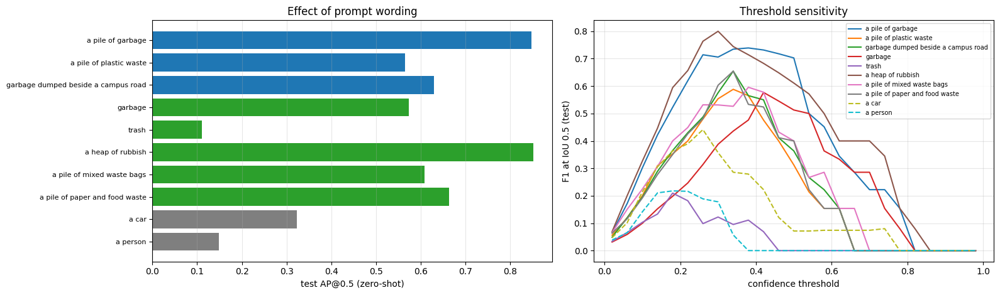

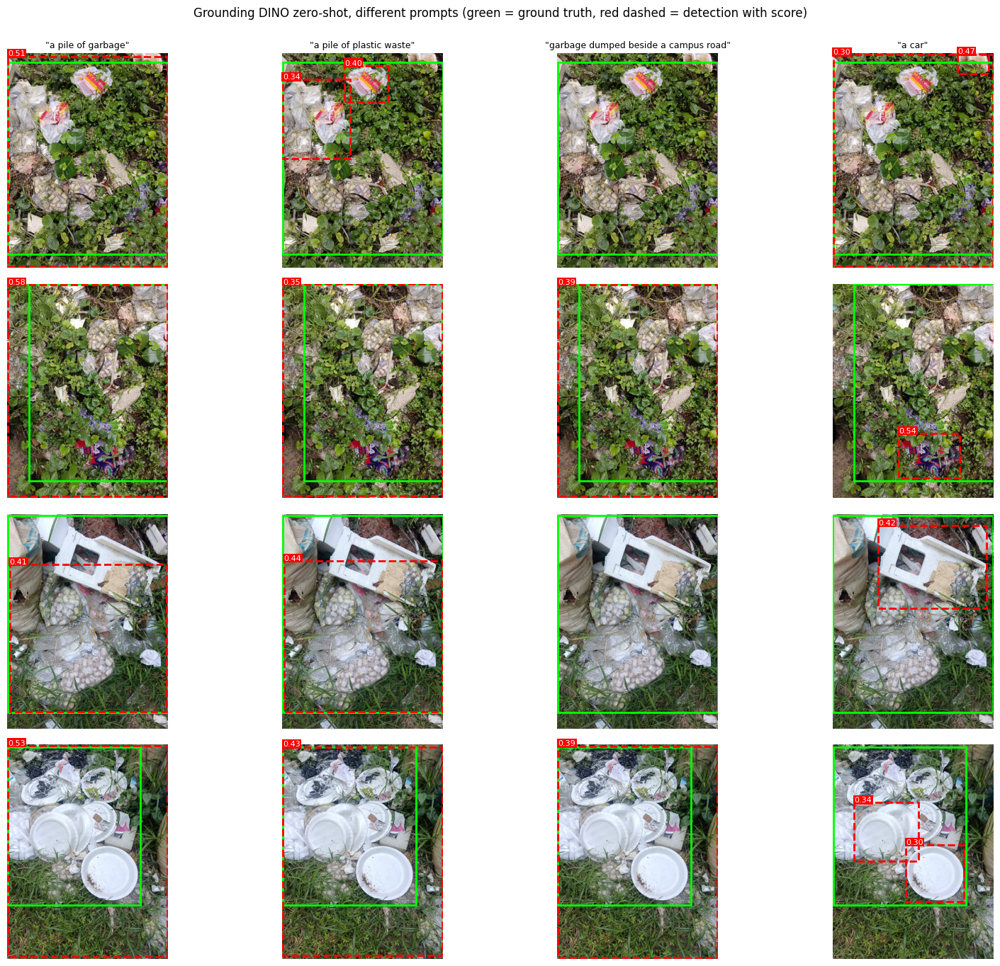

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(16, 4.8))
order = list(GDINO_PROMPTS); colors = {'assignment': 'tab:blue', 'wording': 'tab:green', 'control': 'tab:gray'}
vals = [RESULTS[f'gdino_zs::{p}']['row']['test_AP50'] for p in order]
axs[0].barh(range(len(order)), vals, color=[colors[GDINO_PROMPTS[p]] for p in order]); axs[0].set_yticks(range(len(order))); axs[0].set_yticklabels(order, fontsize=8)
axs[0].invert_yaxis(); axs[0].set_xlabel('test AP@0.5 (zero-shot)'); axs[0].set_title('Effect of prompt wording'); axs[0].grid(axis='x', alpha=.3)
for p in order:
    pr = RESULTS[f'gdino_zs::{p}']['pr']; axs[1].plot(pr['thr'], pr['f1'], label=p, ls='--' if GDINO_PROMPTS[p] == 'control' else '-')
axs[1].set_xlabel('confidence threshold'); axs[1].set_ylabel('F1 at IoU 0.5 (test)'); axs[1].legend(fontsize=7); axs[1].grid(alpha=.3); axs[1].set_title('Threshold sensitivity')
plt.tight_layout(); savefig('gdino_prompt_study'); plt.show()

# the same test images with four different prompts (zero-shot, detections above each prompt's validation-tuned threshold)
show_prompts = ['a pile of garbage', 'a pile of plastic waste', 'garbage dumped beside a campus road', 'a car']
show_recs = TEST[:4]
fig, axs = plt.subplots(len(show_recs), len(show_prompts), figsize=(4.2 * len(show_prompts), 3.4 * len(show_recs)), squeeze=False)
for j, p in enumerate(show_prompts):
    R_ = RESULTS[f'gdino_zs::{p}']
    for i, r in enumerate(show_recs):
        draw_on(axs[i, j], r, dets=R_['preds_test'][r['file_name']], thr=R_['row']['thr'], title=f'"{p}"' if i == 0 else '', fs=8)
plt.suptitle('Grounding DINO zero-shot, different prompts (green = ground truth, red dashed = detection with score)', y=1.0); plt.tight_layout()
savefig('gdino_prompt_gallery'); plt.show()

### 9.4 Interactive text-prompt interface (optional Task 8)

Upload any campus image, type a description, and the interface shows the detected garbage piles with boxes and confidence scores. It uses the fine-tuned Grounding DINO if training worked, otherwise the zero-shot model. Take a screenshot of the running interface for the report.

In [ ]:
LAUNCH_GRADIO = True
import gradio as gr

def gradio_detect(image, prompt, threshold):
    if image is None: return None, pd.DataFrame()
    img = np.array(image.convert('RGB')) if hasattr(image, 'convert') else np.asarray(image)[..., :3]
    H0, W0 = img.shape[:2]; s = min(1.0, 1280 / max(H0, W0))
    if s < 1: img = cv2.resize(img, (round(W0 * s), round(H0 * s)), interpolation=cv2.INTER_AREA)
    h, w = img.shape[:2]; P_UI.set_prompt(prompt or 'a pile of garbage')
    with torch.no_grad(): out = P_UI.forward(P_UI.preprocess(img)[None].to(DEVICE))
    d = P_UI.postprocess(out, [(w, h)])[0]; keep = d['scores'] >= threshold; vis = img.copy(); rows = []
    for (x1, y1, x2, y2), sc in zip(d['boxes'][keep], d['scores'][keep]):
        cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), (255, 40, 40), max(2, w // 300))
        cv2.putText(vis, f'{sc:.2f}', (int(x1) + 4, int(y1) + 24 + 2), cv2.FONT_HERSHEY_SIMPLEX, max(0.7, w / 1400), (255, 255, 255), 2)
        rows.append(dict(x1=int(x1 / s), y1=int(y1 / s), x2=int(x2 / s), y2=int(y2 / s), confidence=round(float(sc), 3)))
    return vis, pd.DataFrame(rows, columns=['x1', 'y1', 'x2', 'y2', 'confidence'])

demo = gr.Interface(fn=gradio_detect,
    inputs=[gr.Image(type='pil', label='RU campus image'), gr.Textbox(value='a pile of garbage', label='Describe the garbage to detect'),
            gr.Slider(0.05, 0.95, value=0.35, step=0.05, label='Confidence threshold')],
    outputs=[gr.Image(label='Detections'), gr.Dataframe(label='Boxes (original-image pixels) and confidence')],
    examples=[[r['path'], 'a pile of garbage', 0.35] for r in TEST[:3]], title='RU campus garbage detection (Grounding DINO)')
if LAUNCH_GRADIO: demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c909b196e649a1935c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 10. Comparative analysis (Tasks 6 and 7)

Everything below is computed from the stored predictions of the **same test images**. Confidence thresholds were fixed on the validation set. With a small test set, treat differences of a few points as uncertain and quote the bootstrap intervals.

In [ ]:
def nice(t): return t.replace('::', ' | ')
CORE_ORDER = ['detr_r50', 'rtdetr_r50vd', 'rtdetr_r18vd', DINO_TAG, 'gdino_tiny::zero-shot', 'gdino_tiny::fine-tuned']
CORE  = [t for t in CORE_ORDER if t in RESULTS]
PRE   = [t for t in RESULTS if RESULTS[t]['row']['group'] == 'pretrained' and 'class-agnostic' in t]
print('models in the main comparison:', CORE); print('original pretrained baselines:', PRE)

def ci_str(t, k):
    lo, hi = RESULTS[t]['ci'][k]; return f"{RESULTS[t]['row'][k]:.3f} [{lo:.2f}-{hi:.2f}]"

cols = ['group', 'test_AP50', 'test_AP', 'test_AP75', 'thr', 'precision', 'recall', 'f1', 'precision_at_0_5', 'recall_at_0_5', 'params_M',
        'fps_fp32', 'lat_model_ms_fp32', 'lat_e2e_ms_fp32', 'fps_fp16', 'peak_mem_MB_fp32', 'train_time_min']
MASTER = pd.DataFrame([RESULTS[t]['row'] for t in PRE + CORE], index=[nice(t) for t in PRE + CORE]).reindex(columns=cols)
for k, nm in (('precision', 'P (95% CI)'), ('recall', 'R (95% CI)'), ('f1', 'F1 (95% CI)')):
    MASTER[nm] = [ci_str(t, k) for t in PRE + CORE]
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
display(MASTER.round(3)); MASTER.round(4).to_csv(OUT / 'master_results.csv')

models in the main comparison: ['detr_r50', 'rtdetr_r50vd', 'rtdetr_r18vd', 'gdino_tiny::zero-shot', 'gdino_tiny::fine-tuned']
original pretrained baselines: ['detr_r50::pretrained (class-agnostic)', 'rtdetr_r50vd::pretrained (class-agnostic)', 'rtdetr_r18vd::pretrained (class-agnostic)']


,group,test_AP50,test_AP,test_AP75,thr,precision,recall,f1,precision_at_0_5,recall_at_0_5,params_M,fps_fp32,lat_model_ms_fp32,lat_e2e_ms_fp32,fps_fp16,peak_mem_MB_fp32,train_time_min,P (95% CI),R (95% CI),F1 (95% CI)
detr_r50 | pretrained (class-agnostic),pretrained,0.003,0.002,0.003,0.14,0.012,0.042,0.019,0.043,0.042,41.525,15.186,58.220,65.851,12.298,294.486,NaN,0.013 [0.00-0.06],0.042 [0.00-0.12],0.019 [0.00-0.08]
rtdetr_r50vd | pretrained (class-agnostic),pretrained,0.012,0.006,0.005,0.37,0.022,0.042,0.029,0.033,0.042,42.891,14.139,65.967,70.728,19.815,316.125,NaN,0.022 [0.00-0.08],0.042 [0.00-0.12],0.029 [0.00-0.10]
rtdetr_r18vd | pretrained (class-agnostic),pretrained,0.071,0.036,0.040,0.22,0.052,0.250,0.086,0.214,0.125,20.175,26.972,32.586,37.076,31.276,199.758,NaN,0.052 [0.02-0.10],0.250 [0.08-0.46],0.086 [0.03-0.16]
detr_r50,fine-tuned,0.890,0.582,0.605,0.90,1.000,0.708,0.829,0.579,0.917,41.502,21.142,42.598,47.299,23.514,294.593,15.127,1.000 [1.00-1.00],0.708 [0.54-0.88],0.829 [0.70-0.93]
rtdetr_r50vd,fine-tuned,0.926,0.662,0.817,0.62,0.840,0.875,0.857,0.840,0.875,42.729,10.086,90.788,99.150,8.919,312.263,17.963,0.840 [0.67-1.00],0.875 [0.75-1.00],0.857 [0.71-1.00]
rtdetr_r18vd,fine-tuned,0.819,0.577,0.776,0.67,0.889,0.667,0.762,0.842,0.667,20.073,8.331,104.894,120.033,16.313,195.310,10.428,0.889 [0.72-1.00],0.667 [0.46-0.83],0.762 [0.59-0.91]
gdino_tiny | zero-shot,pretrained,0.848,0.499,0.479,0.35,0.720,0.750,0.735,1.000,0.542,172.251,2.952,331.705,338.743,4.428,1530.161,NaN,0.720 [0.54-0.91],0.750 [0.58-0.92],0.735 [0.56-0.90]
gdino_tiny | fine-tuned,fine-tuned,0.907,0.563,0.554,0.31,0.857,0.750,0.800,1.000,0.333,172.251,2.931,334.261,341.228,4.383,1530.161,24.030,0.857 [0.69-1.00],0.750 [0.58-0.92],0.800 [0.62-0.94]


### 10.1 Accuracy and efficiency side by side

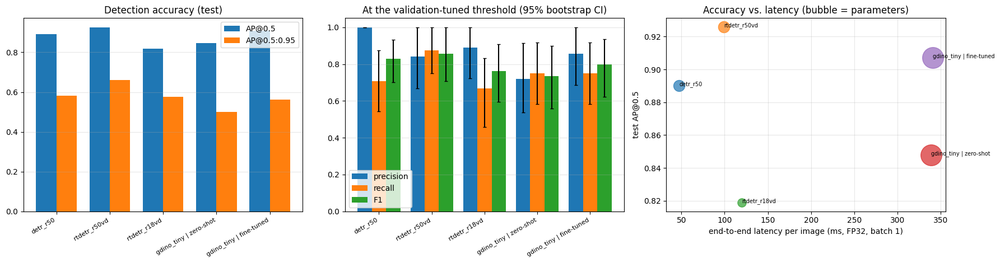

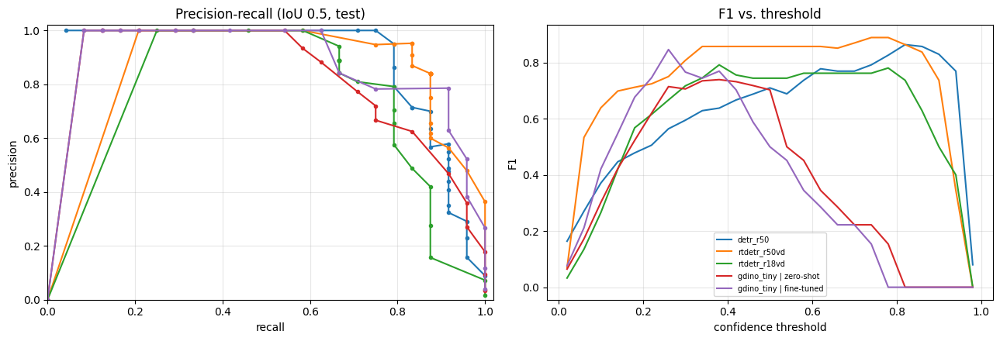

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4.8)); names = [nice(t) for t in CORE]; x = np.arange(len(CORE))
w = 0.38
axs[0].bar(x - w / 2, [RESULTS[t]['row']['test_AP50'] for t in CORE], w, label='AP@0.5'); axs[0].bar(x + w / 2, [RESULTS[t]['row']['test_AP'] for t in CORE], w, label='AP@0.5:0.95')
axs[0].set_xticks(x); axs[0].set_xticklabels(names, rotation=30, ha='right', fontsize=8); axs[0].set_title('Detection accuracy (test)'); axs[0].legend(); axs[0].grid(axis='y', alpha=.3)
for j, (k, lab) in enumerate((('precision', 'precision'), ('recall', 'recall'), ('f1', 'F1'))):
    v = np.array([RESULTS[t]['row'][k] for t in CORE]); lo = np.array([RESULTS[t]['ci'][k][0] for t in CORE]); hi = np.array([RESULTS[t]['ci'][k][1] for t in CORE])
    axs[1].bar(x + (j - 1) * 0.27, v, 0.27, yerr=[v - lo, hi - v], capsize=2, label=lab)
axs[1].set_xticks(x); axs[1].set_xticklabels(names, rotation=30, ha='right', fontsize=8); axs[1].set_title('At the validation-tuned threshold (95% bootstrap CI)'); axs[1].legend(); axs[1].grid(axis='y', alpha=.3)
for t in CORE:
    r = RESULTS[t]['row']; axs[2].scatter(r['lat_e2e_ms_fp32'], r['test_AP50'], s=40 + 4 * r['params_M'], alpha=.7); axs[2].annotate(nice(t), (r['lat_e2e_ms_fp32'], r['test_AP50']), fontsize=7)
axs[2].set_xlabel('end-to-end latency per image (ms, FP32, batch 1)'); axs[2].set_ylabel('test AP@0.5'); axs[2].set_title('Accuracy vs. latency (bubble = parameters)'); axs[2].grid(alpha=.3)
plt.tight_layout(); savefig('comparison_accuracy_efficiency'); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for t in CORE:
    pr = RESULTS[t]['pr']; axs[0].plot(pr['recall'], pr['precision'], marker='.', label=nice(t)); axs[1].plot(pr['thr'], pr['f1'], label=nice(t))
axs[0].set_xlabel('recall'); axs[0].set_ylabel('precision'); axs[0].set_title('Precision-recall (IoU 0.5, test)'); axs[0].set_xlim(0, 1.02); axs[0].set_ylim(0, 1.02); axs[0].grid(alpha=.3)
axs[1].set_xlabel('confidence threshold'); axs[1].set_ylabel('F1'); axs[1].set_title('F1 vs. threshold'); axs[1].grid(alpha=.3); axs[1].legend(fontsize=7)
plt.tight_layout(); savefig('comparison_pr_f1_curves'); plt.show()

### 10.2 Original pretrained versus fine-tuned (Task 6)

Pairs are the original checkpoint (class-agnostic baseline for the closed-set detectors; zero-shot with the best prompt for Grounding DINO) and its fine-tuned version. `d` columns are fine-tuned minus original.

,AP50 before,AP50 after,d AP50,AP before,AP after,d AP,F1 before,F1 after,d F1,R before,R after,P before,P after
model,,,,,,,,,,,,,
detr_r50,0.003,0.890,0.887,0.002,0.582,0.580,0.019,0.829,0.810,0.042,0.708,0.012,1.000
rtdetr_r50vd,0.012,0.926,0.913,0.006,0.662,0.656,0.029,0.857,0.829,0.042,0.875,0.022,0.840
rtdetr_r18vd,0.071,0.819,0.748,0.036,0.577,0.540,0.086,0.762,0.676,0.250,0.667,0.052,0.889
gdino_tiny | fine-tuned,0.848,0.907,0.060,0.499,0.563,0.064,0.735,0.800,0.065,0.750,0.750,0.720,0.857


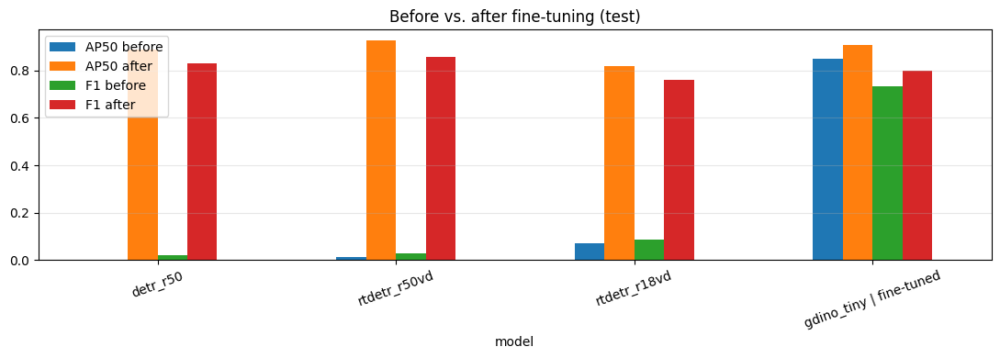

In [ ]:
PAIRS = [('detr_r50::pretrained (class-agnostic)', 'detr_r50'), ('rtdetr_r50vd::pretrained (class-agnostic)', 'rtdetr_r50vd'),
         ('rtdetr_r18vd::pretrained (class-agnostic)', 'rtdetr_r18vd'), (f'{DINO_TAG}::pretrained (class-agnostic)', DINO_TAG),
         ('gdino_tiny::zero-shot', 'gdino_tiny::fine-tuned')]
rows = []
for a, b in PAIRS:
    if a in RESULTS and b in RESULTS:
        ra, rb = RESULTS[a]['row'], RESULTS[b]['row']
        rows.append({'model': nice(b), 'AP50 before': ra['test_AP50'], 'AP50 after': rb['test_AP50'], 'd AP50': rb['test_AP50'] - ra['test_AP50'],
                     'AP before': ra['test_AP'], 'AP after': rb['test_AP'], 'd AP': rb['test_AP'] - ra['test_AP'],
                     'F1 before': ra['f1'], 'F1 after': rb['f1'], 'd F1': rb['f1'] - ra['f1'],
                     'R before': ra['recall'], 'R after': rb['recall'], 'P before': ra['precision'], 'P after': rb['precision']})
PAIR_DF = pd.DataFrame(rows).set_index('model'); display(PAIR_DF.round(3)); PAIR_DF.round(4).to_csv(OUT / 'pretrained_vs_finetuned.csv')
if len(PAIR_DF):
    ax = PAIR_DF[['AP50 before', 'AP50 after', 'F1 before', 'F1 after']].plot.bar(figsize=(11, 4), rot=20); ax.set_title('Before vs. after fine-tuning (test)'); ax.grid(axis='y', alpha=.3)
    plt.tight_layout(); savefig('pretrained_vs_finetuned'); plt.show()

### 10.3 Effect of the training configuration (Task 4)

Augmentation on/off, learning rate and backbone size, all on the same data and evaluation. These are single runs with one random seed, so small differences are not conclusive.

In [ ]:
cfg_tags = [t for t in ['rtdetr_r50vd', 'rtdetr_r50vd_noaug', 'rtdetr_r50vd_lr5e5', 'rtdetr_r18vd', 'detr_r50'] if t in RESULTS]
CFG_DF = pd.DataFrame([RESULTS[t]['row'] for t in cfg_tags], index=cfg_tags)[['test_AP50', 'test_AP', 'f1', 'val_AP50', 'epochs_run', 'best_epoch', 'mean_epoch_time_s', 'train_time_min', 'params_M', 'fps_fp32']]
display(CFG_DF.round(3)); CFG_DF.round(4).to_csv(OUT / 'training_configuration_study.csv')

,test_AP50,test_AP,f1,val_AP50,epochs_run,best_epoch,mean_epoch_time_s,train_time_min,params_M,fps_fp32
rtdetr_r50vd,0.926,0.662,0.857,0.945,39,27,23.067,17.963,42.729,10.086
rtdetr_r50vd_noaug,0.885,0.635,0.690,0.914,28,16,22.917,12.812,42.729,13.702
rtdetr_r50vd_lr5e5,0.889,0.640,0.810,0.895,33,21,23.075,15.232,42.729,13.467
rtdetr_r18vd,0.819,0.577,0.762,0.948,42,30,12.145,10.428,20.073,8.331
detr_r50,0.890,0.582,0.829,0.861,66,46,12.311,15.127,41.502,21.142


### 10.4 Robustness under campus conditions (Task 7)

Each test image is assigned to a bin by the automatic descriptors of Section 1.4 (and by your own labels if `image_metadata.csv` exists). For every model and bin the table gives the **recall** (share of piles found at IoU >= 0.5), the **precision**, and the **mean best IoU** (how well the best box covers the pile). Numbers per bin come from only a handful of images, so look for large, consistent differences across models rather than small ones.


pile_size_bin: images per bin -> {'small pile': 9, 'medium pile': 11, 'large pile': 4}


bin,large pile,medium pile,small pile
model,,,
detr_r50,1.00,0.82,0.44
rtdetr_r50vd,1.00,0.82,0.89
rtdetr_r18vd,0.75,0.73,0.56
gdino_tiny | zero-shot,1.00,0.82,0.56
gdino_tiny | fine-tuned,1.00,0.82,0.56



illumination_bin: images per bin -> {'dark': 11, 'medium light': 5, 'bright': 8}


bin,bright,dark,medium light
model,,,
detr_r50,1.0,0.45,0.8
rtdetr_r50vd,1.0,0.73,1.0
rtdetr_r18vd,1.0,0.36,0.8
gdino_tiny | zero-shot,1.0,0.55,0.8
gdino_tiny | fine-tuned,1.0,0.55,0.8



clutter_bin: images per bin -> {'smooth background': 10, 'medium clutter': 8, 'cluttered': 6}


bin,cluttered,medium clutter,smooth background
model,,,
detr_r50,0.50,0.75,0.8
rtdetr_r50vd,0.50,1.00,1.0
rtdetr_r18vd,0.17,0.88,0.8
gdino_tiny | zero-shot,0.50,0.88,0.8
gdino_tiny | fine-tuned,0.50,0.88,0.8



contrast_bin: images per bin -> {'low contrast': 8, 'medium contrast': 10, 'high contrast': 6}


bin,high contrast,low contrast,medium contrast
model,,,
detr_r50,0.83,0.88,0.5
rtdetr_r50vd,1.00,0.88,0.8
rtdetr_r18vd,0.67,0.88,0.5
gdino_tiny | zero-shot,0.83,0.88,0.6
gdino_tiny | fine-tuned,0.83,0.88,0.6


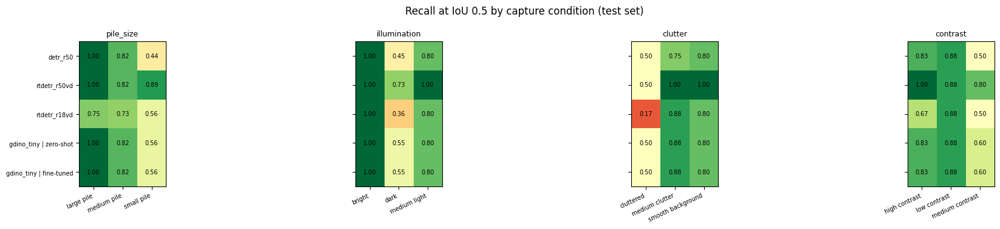

In [ ]:
def strat(tag, factor):
    df = RESULTS[tag]['per_image'].join(FEAT[factor], on='file_name')
    g = df.groupby(factor, observed=True).agg(images=('file_name', 'count'), tp=('tp', 'sum'), fp=('fp', 'sum'), fn=('fn', 'sum'), mean_best_iou=('best_iou', 'mean'))
    g['recall'] = g.tp / (g.tp + g.fn).replace(0, np.nan); g['precision'] = g.tp / (g.tp + g.fp).replace(0, np.nan); return g

user_cols = [c for c in FEAT.columns if c in ('location', 'weather', 'background', 'occlusion', 'view_angle', 'garbage_type') and FEAT[c].notna().any() and (FEAT[c].astype(str) != '').any()]
FACTORS = ['pile_size_bin', 'illumination_bin', 'clutter_bin', 'contrast_bin'] + user_cols
STRAT_TAGS = [t for t in CORE]
all_rows = []
for f in FACTORS:
    for t in STRAT_TAGS:
        g = strat(t, f).reset_index().rename(columns={f: 'bin'}); g.insert(0, 'factor', f); g.insert(1, 'model', nice(t)); all_rows.append(g)
STRAT = pd.concat(all_rows); STRAT.round(3).to_csv(OUT / 'robustness_by_condition.csv', index=False)

for f in FACTORS:
    piv = STRAT[STRAT.factor == f].pivot(index='model', columns='bin', values='recall').reindex([nice(t) for t in STRAT_TAGS])
    n_img = STRAT[(STRAT.factor == f) & (STRAT.model == nice(STRAT_TAGS[0]))].set_index('bin')['images']
    piv = piv[[c for c in piv.columns]]; print(f'\n{f}: images per bin ->', n_img.to_dict()); display(piv.round(2))
fig, axs = plt.subplots(1, 4, figsize=(20, 3.8))
for ax, f in zip(axs, ['pile_size_bin', 'illumination_bin', 'clutter_bin', 'contrast_bin']):
    piv = STRAT[STRAT.factor == f].pivot(index='model', columns='bin', values='recall').reindex([nice(t) for t in STRAT_TAGS])
    im = ax.imshow(piv.values.astype(float), vmin=0, vmax=1, cmap='RdYlGn'); ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns, rotation=25, fontsize=7, ha='right')
    ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index if ax is axs[0] else [], fontsize=7); ax.set_title(f.replace('_bin', ''), fontsize=9)
    for (i, j), v in np.ndenumerate(piv.values.astype(float)): ax.text(j, i, '' if np.isnan(v) else f'{v:.2f}', ha='center', va='center', fontsize=7)
plt.suptitle('Recall at IoU 0.5 by capture condition (test set)'); plt.tight_layout(); savefig('robustness_recall_heatmaps'); plt.show()

### 10.5 Error analysis: false positives, false negatives, poor boxes (Task 7)

Every test image is placed in one outcome class per model:

| Outcome | Meaning |
|---|---|
| correct | every pile found (IoU >= 0.5) and no extra box |
| correct + extra boxes | every pile found, plus at least one false positive |
| partly found | some piles missed, no false positives |
| wrong location / poor box | confident boxes exist but none overlaps a pile enough (IoU < 0.5): a localisation failure |
| missed | no detection above the threshold |

,detr_r50,rtdetr_r50vd,rtdetr_r18vd,gdino_tiny | zero-shot,gdino_tiny | fine-tuned
correct,17,21,16,17,18
correct + extra boxes,0,0,0,1,0
missed,7,0,6,1,3
wrong location / poor box,0,3,2,5,3


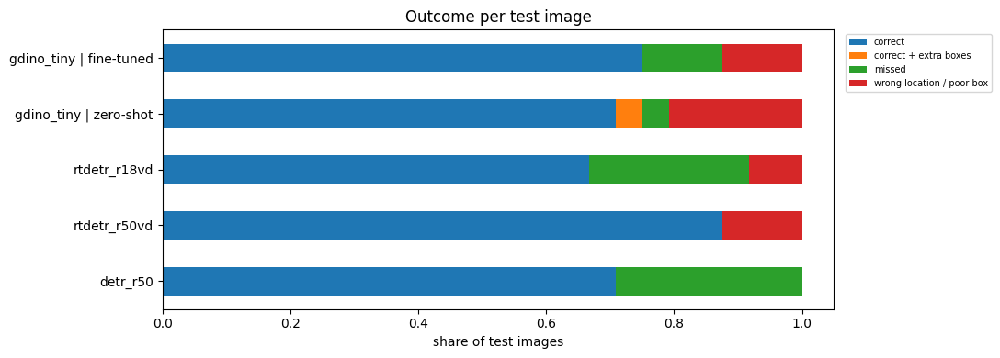

model used for the failure gallery: rtdetr_r50vd


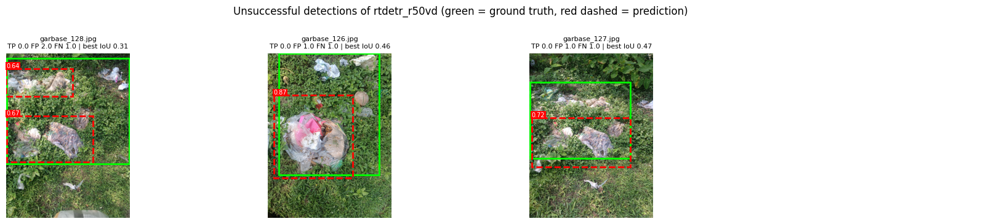


test images in which NO fine-tuned model finds any pile: 3 ['garbase_126.jpg', 'garbase_127.jpg', 'garbase_128.jpg']


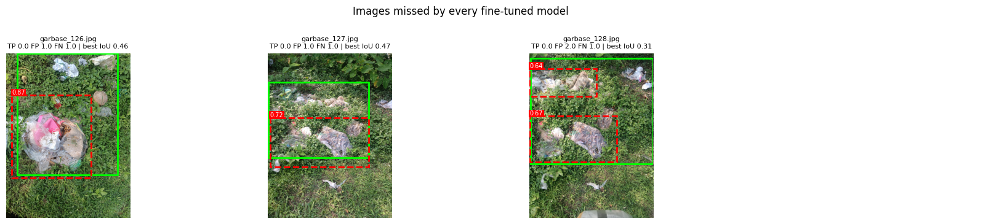

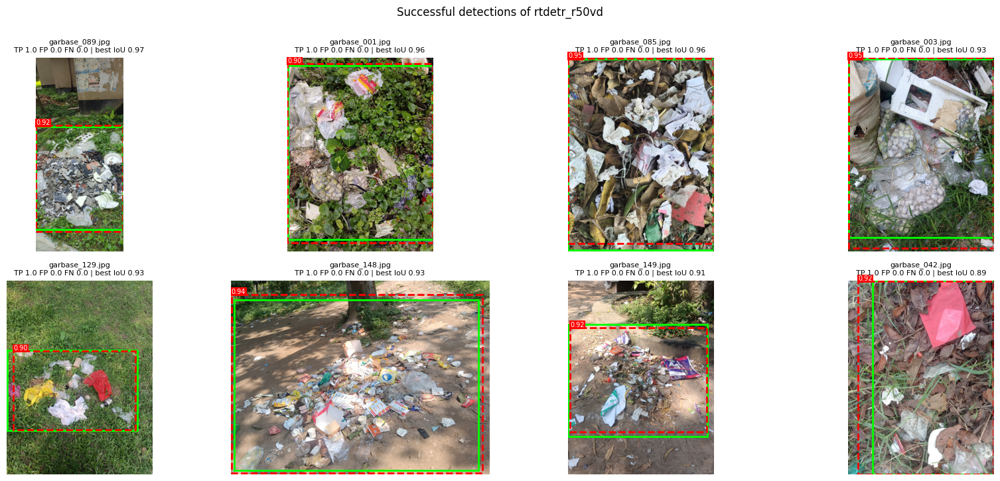

In [ ]:
def outcome(r):
    if r.n_gt == 0: return 'no ground truth'
    if r.tp == r.n_gt and r.fp == 0: return 'correct'
    if r.tp == r.n_gt: return 'correct + extra boxes'
    if r.tp == 0 and r.n_pred == 0: return 'missed'
    if r.tp == 0: return 'wrong location / poor box'
    return 'partly found' if r.fp == 0 else 'partly found + extra boxes'

OUTC = pd.DataFrame({nice(t): RESULTS[t]['per_image'].apply(outcome, axis=1).value_counts() for t in CORE}).fillna(0).astype(int)
display(OUTC); OUTC.to_csv(OUT / 'error_outcomes.csv')
ax = (OUTC / OUTC.sum()).T.plot.barh(stacked=True, figsize=(11, 4)); ax.set_xlabel('share of test images'); ax.set_title('Outcome per test image'); ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1))
plt.tight_layout(); savefig('error_outcomes'); plt.show()

FT_ONLY = [t for t in CORE if RESULTS[t]['row']['group'] == 'fine-tuned']
BEST_FT = max(FT_ONLY, key=lambda t: RESULTS[t]['row']['test_AP50']); print('model used for the failure gallery:', BEST_FT)
byfile = {r['file_name']: r for r in TEST}
def gallery(tag, files, fname, title, ncol=4):
    n = len(files)
    if n == 0: print('nothing to show for:', title); return
    nrow = math.ceil(n / ncol); fig, axs = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 3.6 * nrow), squeeze=False)
    for ax in axs.ravel(): ax.axis('off')
    for ax, fn in zip(axs.ravel(), files):
        pi = RESULTS[tag]['per_image'].set_index('file_name').loc[fn]
        draw_on(ax, byfile[fn], dets=RESULTS[tag]['preds_test'][fn], thr=RESULTS[tag]['row']['thr'], title=f'{fn}\nTP {pi.tp} FP {pi.fp} FN {pi.fn} | best IoU {pi.best_iou:.2f}', fs=7)
    plt.suptitle(title, y=1.0); plt.tight_layout(); savefig(fname); plt.show()

pi = RESULTS[BEST_FT]['per_image']; bad = pi[(pi.fn > 0) | (pi.fp > 0)].sort_values('best_iou').file_name.tolist()[:8]
gallery(BEST_FT, bad, 'failures_best_model', f'Unsuccessful detections of {nice(BEST_FT)} (green = ground truth, red dashed = prediction)')
hard = [r['file_name'] for r in TEST if all(RESULTS[t]['per_image'].set_index('file_name').loc[r['file_name']].tp == 0 for t in FT_ONLY)]
print(f'\ntest images in which NO fine-tuned model finds any pile: {len(hard)}', hard)
gallery(BEST_FT, hard[:8], 'failures_all_models', 'Images missed by every fine-tuned model')
good = pi.sort_values('best_iou', ascending=False).file_name.tolist()[:8]
gallery(BEST_FT, good, 'successes_best_model', f'Successful detections of {nice(BEST_FT)}')

## 11. Qualitative comparison on identical images

Columns: ground truth, then every model in the main comparison (detections above each model's tuned threshold). Rows: the images where the models agree most (successes), and where they differ or fail most.

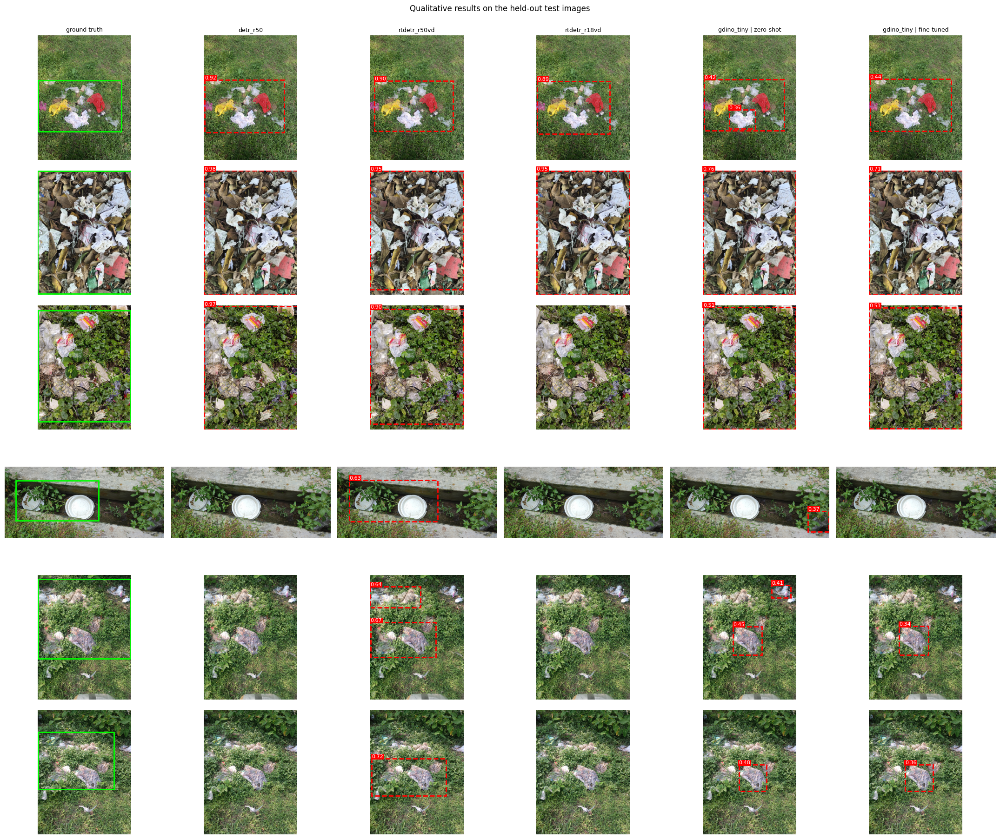

In [ ]:
mean_iou = pd.concat({t: RESULTS[t]['per_image'].set_index('file_name').best_iou for t in CORE}, axis=1).mean(axis=1).sort_values()
spread = pd.concat({t: RESULTS[t]['per_image'].set_index('file_name').best_iou for t in CORE}, axis=1).std(axis=1).sort_values(ascending=False)
pick = list(mean_iou.index[-2:]) + list(spread.index[:2]) + list(mean_iou.index[:2]); pick = list(dict.fromkeys(pick))[:6]
fig, axs = plt.subplots(len(pick), len(CORE) + 1, figsize=(3.6 * (len(CORE) + 1), 3.0 * len(pick)), squeeze=False)
for i, fn in enumerate(pick):
    draw_on(axs[i, 0], byfile[fn], title='ground truth' if i == 0 else '', fs=8)
    for j, t in enumerate(CORE):
        draw_on(axs[i, j + 1], byfile[fn], gt=False, dets=RESULTS[t]['preds_test'][fn], thr=RESULTS[t]['row']['thr'], title=nice(t) if i == 0 else '', fs=8)
plt.suptitle('Qualitative results on the held-out test images', y=1.0); plt.tight_layout(); savefig('qualitative_all_models'); plt.show()

## 12. Save everything for the report and the deliverables

Writes to `Ru_Garbase/Experiments/`: the master tables (CSV), the configuration of every experiment (JSON), the environment record, per-model predictions, and a ZIP with all figures. Trained weights are in `Experiments/<tag>/best/` (Hugging Face format) and `Experiments/dino_r50_4scale/checkpoint_best.pth`.

In [ ]:
env = dict(gpu=GPU_NAME, torch=torch.__version__, torchvision=torchvision.__version__, transformers=transformers.__version__, albumentations=A.__version__,
           seed=SEED, cache_max_side=CACHE_MAX_SIDE, iou_match=IOU_MATCH, fixed_conf=CONF_FIXED, quick_test=QUICK_TEST, gdino_nms=GDINO_NMS,
           best_gdino_prompt=BEST_PROMPT, train_images=len(TRAIN), val_images=len(VAL), test_images=len(TEST),
           train_boxes=int(sum(len(r['boxes']) for r in TRAIN)), val_boxes=int(sum(len(r['boxes']) for r in VAL)), test_boxes=int(sum(len(r['boxes']) for r in TEST)),
           input_sizes={k: v['S'] for k, v in MODEL_ZOO.items()}, dino_input='short side 800, long side <= 1333 (aspect preserved)')
json.dump(env, open(OUT / 'environment.json', 'w'), indent=1); json.dump(EXPERIMENTS, open(OUT / 'experiment_configs.json', 'w'), indent=1, default=str)
pred_dir = OUT / 'predictions'; pred_dir.mkdir(exist_ok=True)
for t in RESULTS:
    d = {fn: dict(boxes=v['boxes'].tolist(), scores=v['scores'].tolist()) for fn, v in RESULTS[t]['preds_test'].items()}
    json.dump(d, open(pred_dir / (re.sub(r'[^A-Za-z0-9_.-]+', '_', t)[:80] + '_test.json'), 'w'))
all_rows = pd.DataFrame([v['row'] for v in RESULTS.values()]); all_rows.to_csv(OUT / 'all_results_rows.csv', index=False)
shutil.make_archive(str(OUT / 'figures_archive'), 'zip', FIG_DIR)
print('saved:', sorted(p.name for p in OUT.iterdir() if p.is_file()))

print('\n=== Key numbers for the report (test set, thresholds tuned on validation) ===')
for t in PRE + CORE:
    r = RESULTS[t]['row']
    print(f"{nice(t):48s} AP50 {r['test_AP50']:.3f} | AP {r['test_AP']:.3f} | P {r['precision']:.3f} R {r['recall']:.3f} F1 {r['f1']:.3f} | "
          f"{r.get('fps_fp32', float('nan')):.1f} FPS | {r.get('lat_e2e_ms_fp32', float('nan')):.0f} ms | {r.get('params_M', float('nan')):.0f} M params")

saved: ['Dataset_Card.md', 'all_results_rows.csv', 'dataset_split_table.csv', 'environment.json', 'error_outcomes.csv', 'experiment_configs.json', 'figures_archive.zip', 'gdino_zero_shot_prompts.csv', 'gdino_zeroshot_vs_finetuned_by_prompt.csv', 'image_features.csv', 'master_results.csv', 'pretrained_vs_finetuned.csv', 'robustness_by_condition.csv', 'training_configuration_study.csv']

=== Key numbers for the report (test set, thresholds tuned on validation) ===
detr_r50 | pretrained (class-agnostic)           AP50 0.003 | AP 0.002 | P 0.013 R 0.042 F1 0.019 | 15.2 FPS | 66 ms | 42 M params
rtdetr_r50vd | pretrained (class-agnostic)       AP50 0.012 | AP 0.006 | P 0.022 R 0.042 F1 0.029 | 14.1 FPS | 71 ms | 43 M params
rtdetr_r18vd | pretrained (class-agnostic)       AP50 0.071 | AP 0.036 | P 0.052 R 0.250 F1 0.086 | 27.0 FPS | 37 ms | 20 M params
detr_r50                                         AP50 0.890 | AP 0.582 | P 1.000 R 0.708 F1 0.829 | 21.1 FPS | 47 ms | 42 M params
rtdetr_r5